# 01 · 苍穹外卖：项目概述、环境搭建

来源：本地资料 `讲义.rar / 讲义/day01/苍穹外卖-day01.md` 与 `PPT.rar / PPT/day01-项目概述、环境搭建.pptx`，原压缩包位于 `D:/baidudisk/BaiduNetdiskDownload`。整理日期：2026-10-09。

本章沿用已有 JavaWeb 笔记的结构：按讲义顺序保留正文、代码、表格和配图，对照 PPT 补齐关键概念，把“补充”和“勘误”放在相应小节后。图片直接内嵌 Notebook，离线打开不依赖外部 assets 目录。Java、SQL、Nginx 与 XML 代码用于阅读和跟练，不在 Python 内核中执行。

学习目标：说明商家管理端与用户小程序的职责，理解 Maven 三个子模块的分工，串联一次员工登录请求，完成 Nginx 与后端联调，并用 Knife4j 查看和测试接口。

> **资料范围。** 当前两个压缩包提供 PPT、Markdown 和图片。正文提到的后端初始工程、Nginx 运行包、`sky.sql`、产品原型、接口 JSON 和数据库设计文档，需要使用课程的对应资料；它们没有包含在本次笔记附件中。本文保留讲义中的操作示例，未在你的电脑上安装服务或修改数据库。


## 本章跟练路线（补充）

| 顺序 | 本章任务 | 完成标志 |
| --- | --- | --- |
| 1 | 认识开发流程、角色和三套环境 | 能解释需求、设计、编码、测试、运维分别产生什么 |
| 2 | 阅读商家端和用户端原型 | 能把页面操作对应到接口与数据库表 |
| 3 | 启动 Nginx 管理端 | `http://localhost/` 可打开登录页 |
| 4 | 导入 Maven 初始工程与数据库 | 模块依赖正常，`sky_take_out` 有11张业务表 |
| 5 | 启动后端并调试登录 | `/admin/employee/login` 能完成账号、密码、状态校验 |
| 6 | 配置 Nginx 反向代理 | 前端 `/api/employee/login` 能转发给后端 |
| 7 | 按课程完善密码比对 | 数据库与 Java 使用相同的 MD5 表示，登录结果符合预期 |
| 8 | 导入接口文档、接入 Knife4j | `http://localhost:8080/doc.html` 可展示并调试接口 |

### 一次请求经过哪些组件

```text
管理端浏览器：POST http://localhost/api/employee/login
    Nginx：将 /api/ 替换为 /admin/，转发到8080端口
后端：POST http://localhost:8080/admin/employee/login
    EmployeeController：接收 DTO，调用 Service，生成 JWT，返回 VO
    EmployeeServiceImpl：按用户名查询，检查密码与账号状态
    EmployeeMapper：查询 MySQL employee 表
浏览器：接收 Result<EmployeeLoginVO>，后续请求携带 token
```

第一章以管理端初始登录为联调入口。用户端微信登录、订单支付、Redis 缓存和 WebSocket 等功能在后续章节展开。


## 课程内容

> **PPT对照：** 第1—6页：课程目标与项目效果。

- 软件开发整体介绍
- 苍穹外卖项目介绍
- 开发环境搭建
- 导入接口文档
- Swagger


**项目整体效果展示：**

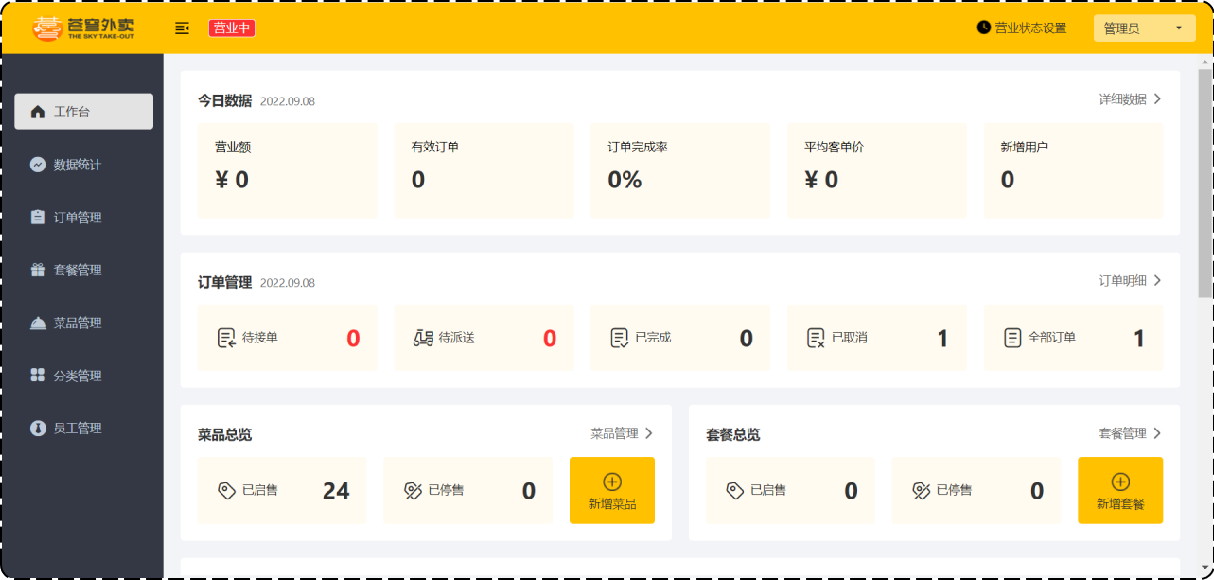

         管理端-外卖商家使用

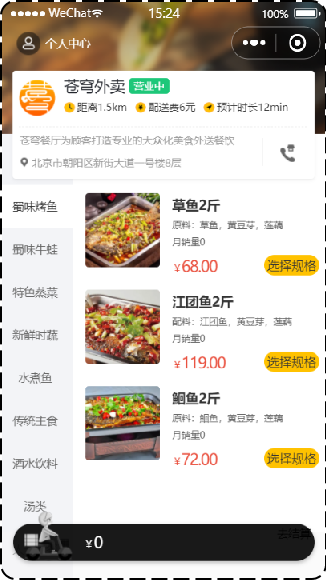

     用户端-点餐用户使用

当我们完成该项目的学习，可以培养以下能力：

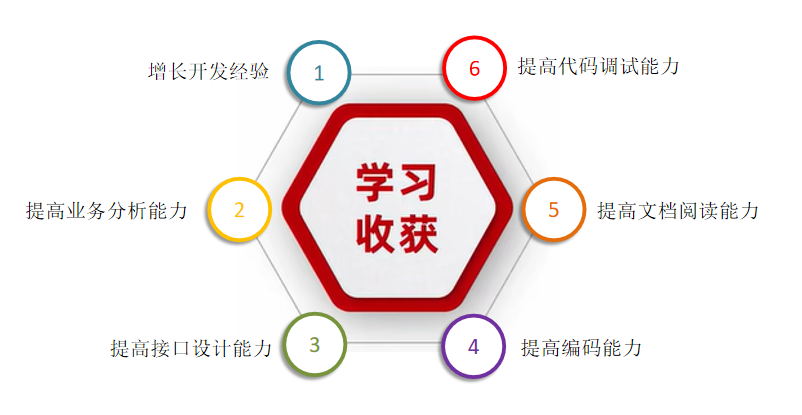


### 本章阅读方式（补充）

PPT 用于把握主线，讲义提供具体操作与代码。先记住“原型确定业务、接口约定数据、分层代码实现、联调验证结果”，再逐步对照截图跟练。截图中的端口、IP、目录和版本以课程环境为例，应以自己的项目配置为准。


## 1. 软件开发整体介绍

> **PPT对照：** 第7—12页。

作为一名软件开发工程师,我们需要了解在软件开发过程中的开发流程， 以及软件开发过程中涉及到的岗位角色，角色的分工、职责， 并了解软件开发中涉及到的三种软件环境。那么这一小节，我们将从 软件开发流程、角色分工、软件环境 三个方面整体介绍一下软件开发。


### 1.1 软件开发流程

> **PPT对照：** 第8页。

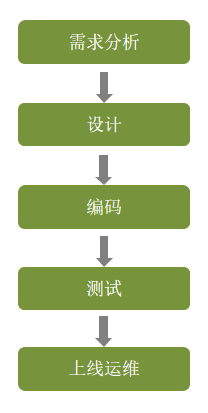


**1). 第1阶段: 需求分析**

完成需求规格说明书、产品原型编写。  

需求规格说明书， 一般来说就是使用 Word 文档来描述当前项目的各个组成部分，如：系统定义、应用环境、功能规格、性能需求等，都会在文档中描述。**例如：**

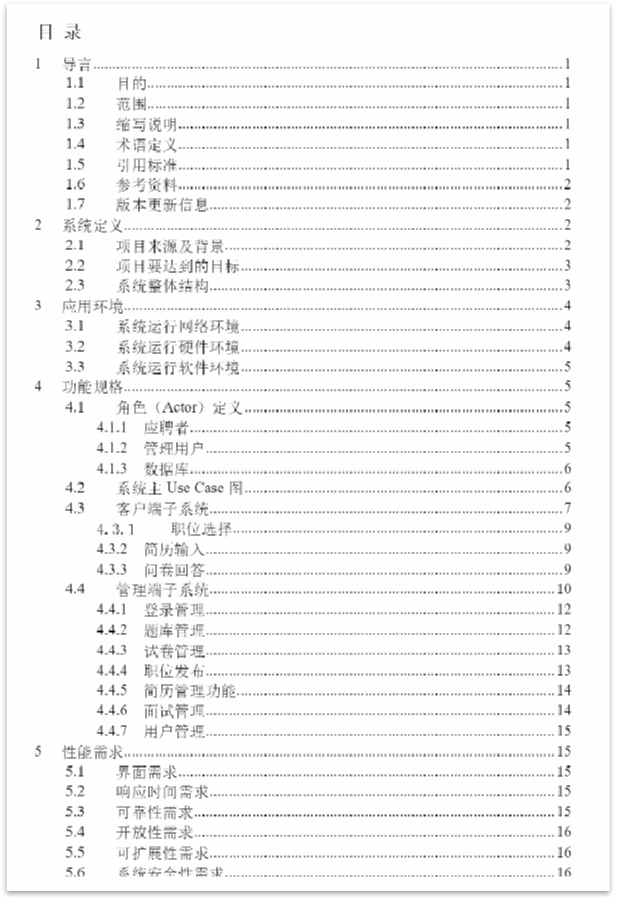

产品原型，一般是通过网页(html)的形式展示当前的页面展示什么样的数据, 页面的布局是什么样子的，点击某个菜单，打开什么页面，点击某个按钮，出现什么效果，都可以通过产品原型看到。 **例如：**

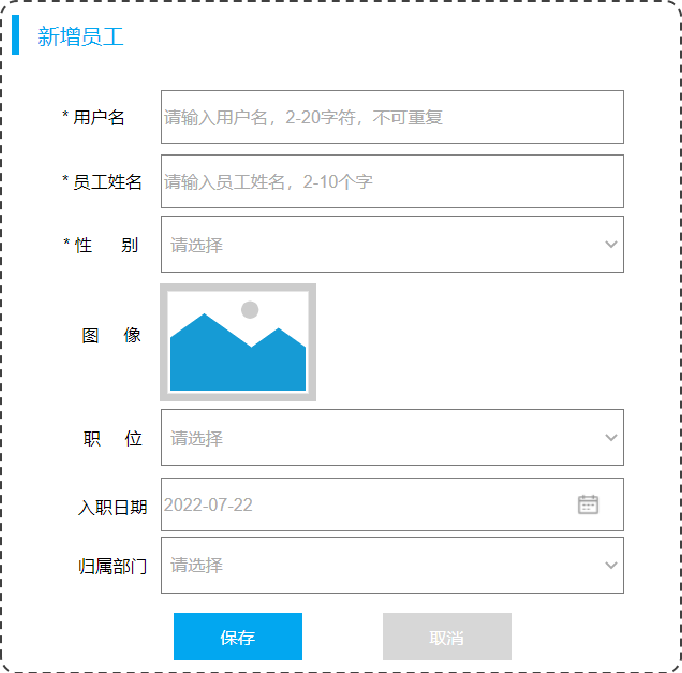


**2). 第2阶段: 设计**

设计的内容包含 UI设计、数据库设计、接口设计。

UI设计：用户界面的设计，主要设计项目的页面效果，小到一个按钮，大到一个页面布局，还有人机交互逻辑的体现。**例如：**

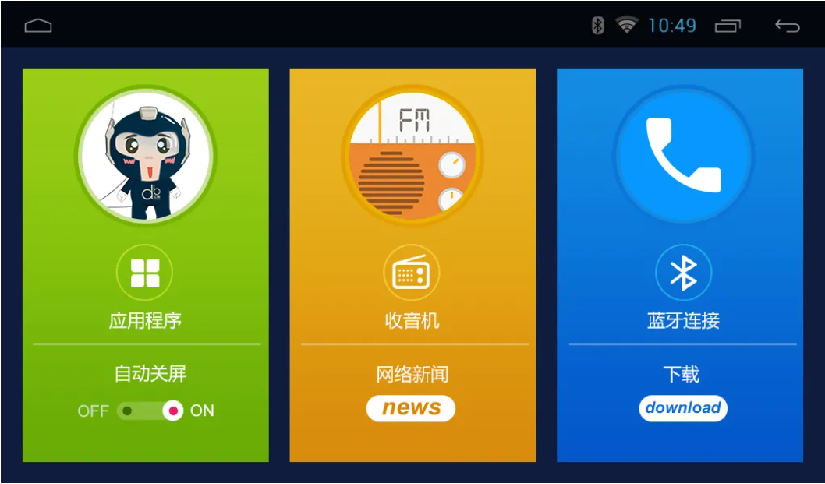

数据库设计：需要设计当前项目中涉及到哪些数据库，每一个数据库里面包含哪些表，这些表结构之间的关系是什么样的，表结构中包含哪些字段。**例如：**

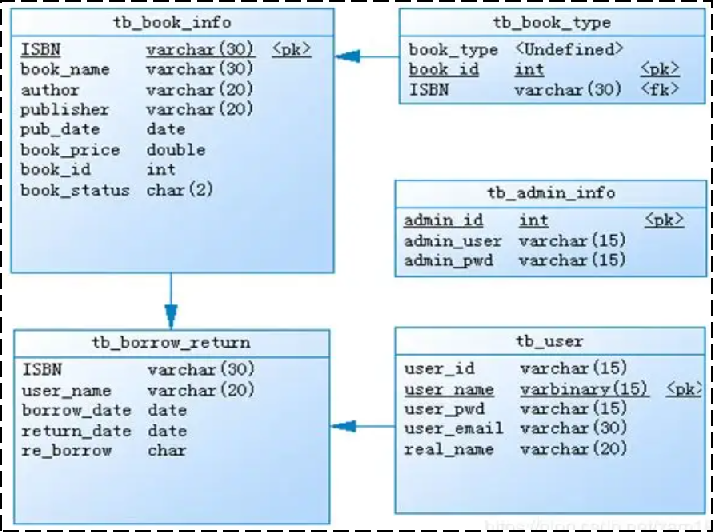

接口设计：通过分析原型图，首先，粗粒度地分析每个页面有多少接口，然后，再细粒度地分析每个接口的传入参数，返回值参数，同时明确接口路径及请求方式。**例如：**

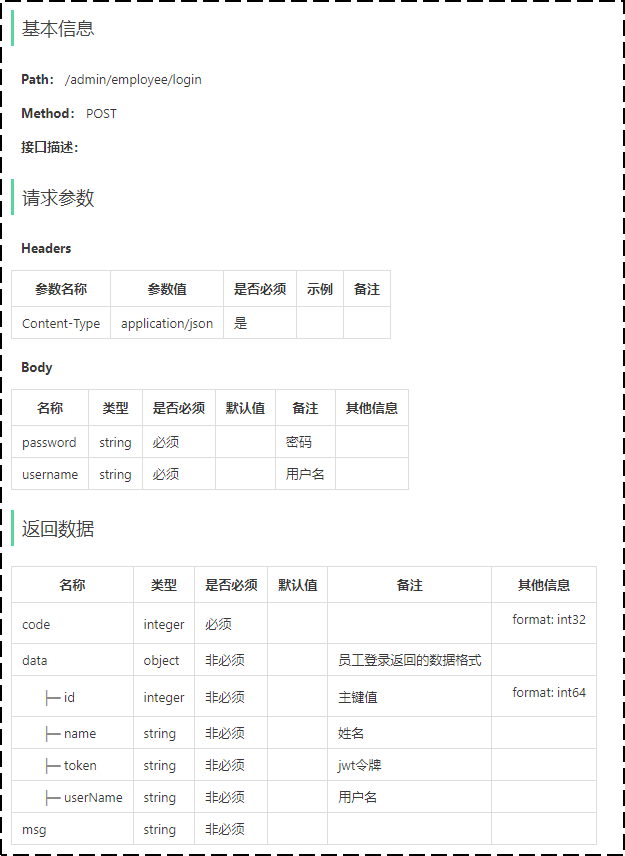


**3). 第3阶段: 编码**

编写项目代码、并完成单元测试。

项目代码编写：作为软件开发工程师，我们需要对项目的模块功能分析后，进行编码实现。

单元测试：编码实现完毕后，进行单元测试，单元测试通过后再进入到下一阶段。**例如：**

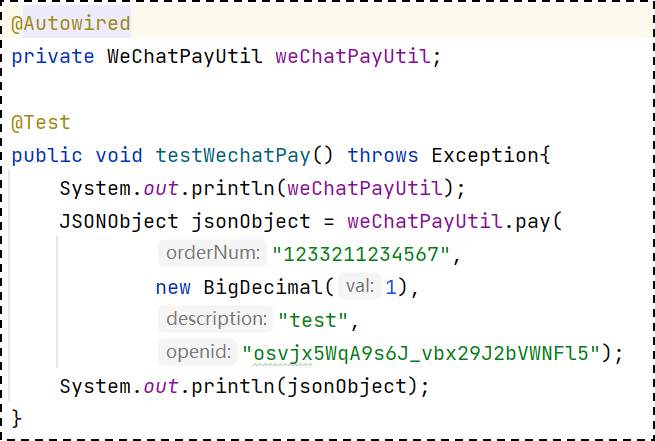


**4). 第4阶段: 测试**

在该阶段中主要由测试人员, 对部署在测试环境的项目进行功能测试, 并出具测试报告。


**5). 第5阶段: 上线运维**

在项目上线之前， 会由运维人员准备服务器上的软件环境安装、配置， 配置完毕后， 再将我们开发好的项目，部署在服务器上运行。


### 开发流程的产物（补充）

| 阶段 | 输入 | 输出 | 自己要能检查的内容 |
| --- | --- | --- | --- |
| 需求分析 | 用户诉求、业务规则 | 需求说明书、产品原型 | 谁使用、做什么、操作失败怎么办 |
| 设计 | 原型与需求 | UI、数据库模型、接口文档 | 字段、约束、请求与响应能否对齐 |
| 编码 | 设计文档 | 代码与单元测试 | 正常分支和异常分支是否实现 |
| 测试 | 可运行版本 | 测试结果与缺陷记录 | 页面、接口与数据是否一致 |
| 上线运维 | 通过验收的版本 | 部署服务、监控与回滚方案 | 配置、日志、数据备份是否可追踪 |

实际开发允许反馈到前面的阶段。例如员工“禁用”后不能登录，需要同时明确页面操作、接口参数、数据库状态和 Service 校验规则。


### 1.2 角色分工

> **PPT对照：** 第10页。

在对整个软件开发流程熟悉后， 我们还有必要了解一下在整个软件开发流程中涉及到的岗位角色，以及各个角色的职责分工。

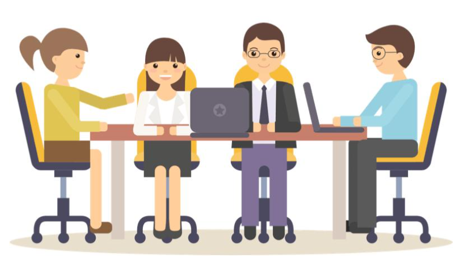

| 岗位/角色                           | 对应阶段                      | 职责/分工                                  |
| :---------------------------------- | ----------------------------- | :----------------------------------------- |
| 项目经理                            | 全阶段                        | 对整个项目负责，任务分配、把控进度         |
| 产品经理                            | 需求分析                      | 进行需求调研，输出需求调研文档、产品原型等 |
| UI设计师                            | 设计                          | 根据产品原型输出界面效果图                 |
| 架构师                              | 设计                          | 项目整体架构设计、技术选型等               |
| 开发工程师 | 编码 | 功能代码实现      |
| 测试工程师                          | 测试                          | 编写测试用例，输出测试报告                 |
| 运维工程师                          | 上线运维                      | 软件环境搭建、项目上线                     |


上述我们讲解的角色分工, 是在一个项目组中比较标准的角色分工, 但是在实际的项目中, 有一些项目组由于人员配置紧张, 可能并没有专门的架构师或测试人员, 这个时候可能需要有项目经理或者程序员兼任。


### 协作中的交接点（补充）

开发者拿到产品原型后，先和产品确认业务规则，再和前端确认字段、路径、请求方式及错误响应。一个人可以兼任多种角色，但需求确认、代码自测和上线验收仍应有明确记录。


### 1.3 软件环境

> **PPT对照：** 第12页。

作为软件开发工程师，在编码的过程中就不可避免地会接触多种软件环境，我们主要来分析在工作中经常遇到的三套环境， 分别是: 开发环境、测试环境、生产环境。 接下来，我们分别介绍一下这三套环境的作用和特点。


**1). 开发环境(development)**

我们作为软件开发人员，在开发阶段使用的环境，就是开发环境，一般外部用户无法访问。

比如，我们在开发中使用的MySQL数据库和其他的一些常用软件，我们可以安装在本地， 也可以安装在一台专门的服务器中， 这些应用软件仅仅在软件开发过程中使用， 项目测试、上线时，我们不会使用这套环境了，这个环境就是开发环境。


**2). 测试环境(testing)**

当软件开发工程师，将项目的功能模块开发完毕，并且单元测试通过后，就需要将项目部署到测试服务器上，让测试人员对项目进行测试。那这台测试服务器就是专门给测试人员使用的环境， 也就是测试环境，用于项目测试，一般外部用户无法访问。


**3). 生产环境(production)**

当项目开发完毕，并且由测试人员测试通过之后，就可以上线项目，将项目部署到线上环境，并正式对外提供服务，这个线上环境也称之为生产环境。


         **开发环境**                                                         **测试环境**                                                **生产环境**

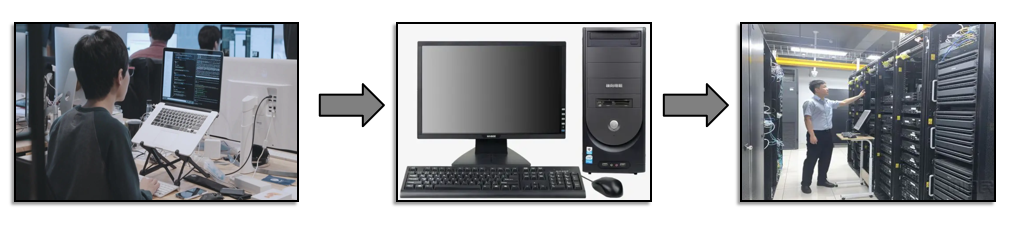


首先，会在开发环境中进行项目开发，往往开发环境大多数都是本地的电脑环境和局域网内的环境，当开发完毕后，然后会把项目部署到测试环境，测试环境一般是一台独立测试服务器的环境，项目测试通过后，最终把项目部署到生产环境，生产环境可以是机房或者云服务器等线上环境。


### 环境隔离（补充）

开发、测试、生产应使用各自的数据库、账号、配置和第三方服务凭据。Spring Boot 可用不同 profile 管理配置，但实际启用哪个 profile，要查看初始工程的 `application.yml`，不要凭文件名推断。

生产数据不直接用于随意测试；数据库密码、JWT 密钥和 OSS 凭据不提交到 Git。启动故障先确认环境和配置，再改代码。


## 2. 苍穹外卖项目介绍

> **PPT对照：** 第14—20页。

在开发苍穹外卖这个项目之前，我们需要全方位的来介绍一下当前我们学习的这个项目。接下来，我们将从项目简介、产品原型、技术选型三个方面来介绍苍穹外卖这个项目。


### 2.1 项目介绍

> **PPT对照：** 第15—16页。

本项目（苍穹外卖）是专门为餐饮企业（餐厅、饭店）定制的一款软件产品，包括 系统管理后台 和 小程序端应用 两部分。其中系统管理后台主要提供给餐饮企业内部员工使用，可以对餐厅的分类、菜品、套餐、订单、员工等进行管理维护，对餐厅的各类数据进行统计，同时也可进行来单语音播报功能。小程序端主要提供给消费者使用，可以在线浏览菜品、添加购物车、下单、支付、催单等。

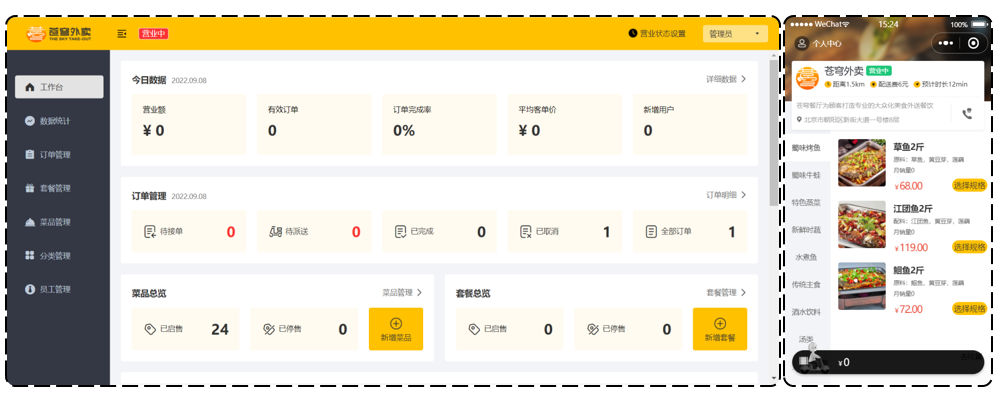


接下来，通过功能架构图来展示**管理端**和**用户端**的具体业务功能模块。

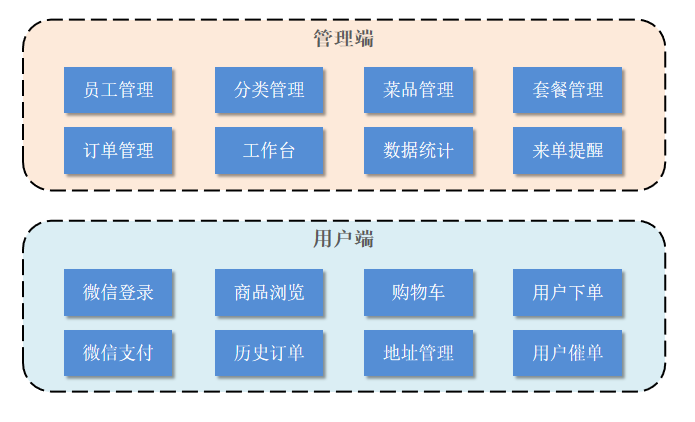

**1). 管理端功能**

员工登录/退出 , 员工信息管理 , 分类管理 , 菜品管理 , 套餐管理 , 菜品口味管理 , 订单管理 ，数据统计，来单提醒。

**2). 用户端功能**

 微信登录 , 收件人地址管理 , 用户历史订单查询 , 菜品规格查询 , 购物车功能 , 下单 , 支付、分类及菜品浏览。


### 两端的业务边界（PPT补充）

PPT第16页还列出了管理端“工作台”和用户端“微信支付、用户催单”。管理端负责商家经营维护，用户端负责消费流程，两端通过同一后端服务访问各自权限范围内的数据。

可以沿着一条业务链理解数据：分类组织菜品，菜品及套餐供用户加入购物车，下单时生成订单和订单明细，商家处理订单，统计模块再汇总业务数据。本章只建立整体认识。


### 2.2 产品原型

> **PPT对照：** 第18页。

**产品原型**，用于展示项目的业务功能，一般由产品经理进行设计。

> **注意事项：** 产品原型主要用于展示项目的功能，并不是最终的页面效果。


在课程资料的产品原型文件夹下,提供了两份产品原型。

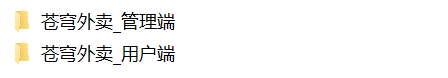 

**管理端原型图：**

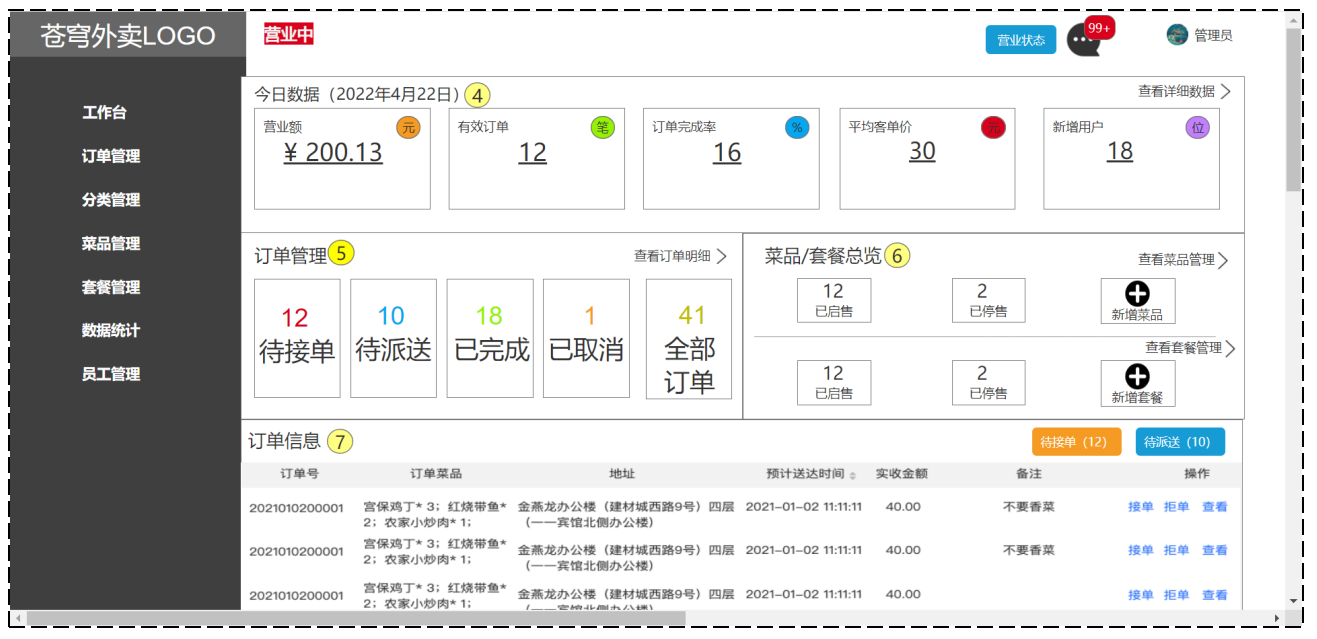

**用户端原型图：**

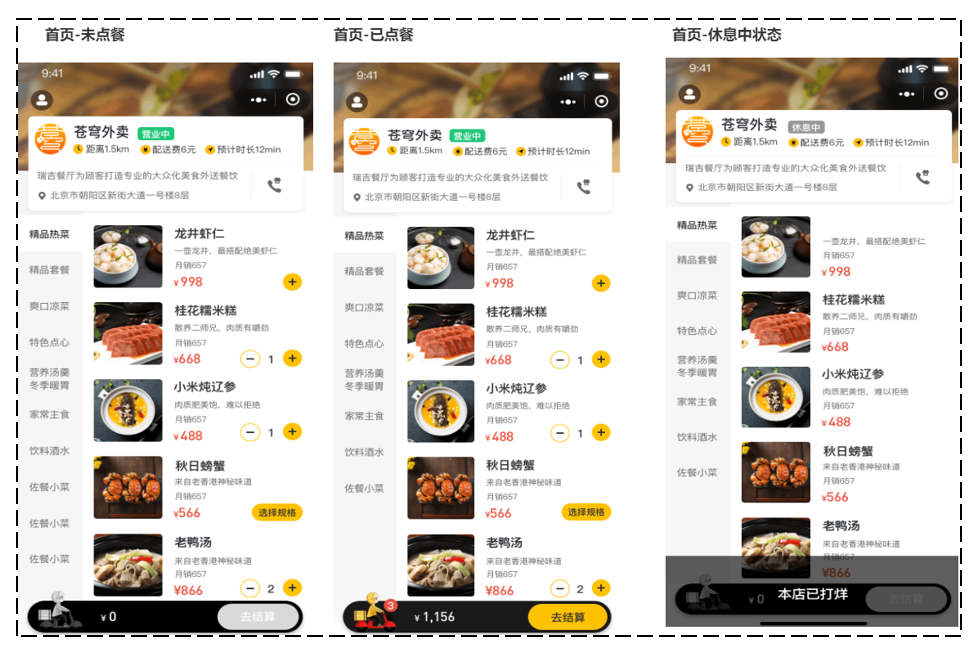

**1). 管理端**

餐饮企业内部员工使用。 主要功能有: 

| 模块      | 描述                                                         |
| --------- | ------------------------------------------------------------ |
| 登录/退出 | 内部员工必须登录后,才可以访问系统管理后台                    |
| 员工管理  | 管理员可以在系统后台对员工信息进行管理，包含查询、新增、编辑、禁用等功能 |
| 分类管理  | 主要对当前餐厅经营的 菜品分类 或 套餐分类 进行管理维护， 包含查询、新增、修改、删除等功能 |
| 菜品管理  | 主要维护各个分类下的菜品信息，包含查询、新增、修改、删除、启售、停售等功能 |
| 套餐管理  | 主要维护当前餐厅中的套餐信息，包含查询、新增、修改、删除、启售、停售等功能 |
| 订单管理  | 主要维护用户在移动端下的订单信息，包含查询、取消、派送、完成，以及订单报表下载等功能 |
| 数据统计  | 主要完成对餐厅的各类数据统计，如营业额、用户数量、订单等     |


**2). 用户端**

移动端应用主要提供给消费者使用。主要功能有:

| 模块        | 描述                                                         |
| ----------- | ------------------------------------------------------------ |
| 登录/退出   | 用户需要通过微信授权后登录使用小程序进行点餐                 |
| 点餐-菜单   | 在点餐界面需要展示出菜品分类/套餐分类, 并根据当前选择的分类加载其中的菜品信息, 供用户查询选择 |
| 点餐-购物车 | 用户选中的菜品就会加入用户的购物车, 主要包含 查询购物车、加入购物车、删除购物车、清空购物车等功能 |
| 订单支付    | 用户选完菜品/套餐后, 可以对购物车菜品进行结算支付, 这时就需要进行订单的支付 |
| 个人信息    | 在个人中心页面中会展示当前用户的基本信息, 用户可以管理收货地址, 也可以查询历史订单数据 |


### 从原型读出接口需求（补充）

以登录页为例：用户名和密码是请求参数，登录成功后页面需要显示姓名并保存 token，因此返回 VO 应提供身份显示信息与令牌。还要明确账号不存在、密码错误、账号禁用时显示什么结果。

原型确认功能与交互，UI效果图确认视觉呈现，接口文档确认前后端交换数据的约定。


### 2.3 技术选型

> **PPT对照：** 第20页。

关于本项目的技术选型, 我们将会从 用户层、网关层、应用层、数据层 这几个方面进行介绍，主要用于展示项目中使用到的技术框架和中间件等。

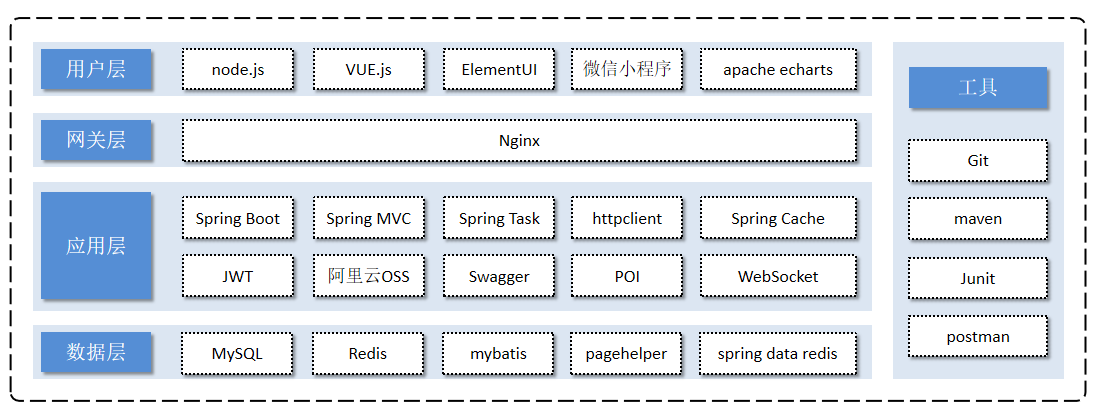


**1). 用户层**

本项目中在构建系统管理后台的前端页面，我们会用到H5、Vue.js、ElementUI、apache echarts(展示图表)等技术。而在构建移动端应用时，我们会使用到微信小程序。


**2). 网关层**

Nginx是一个服务器，主要用来作为Http服务器，部署静态资源，访问性能高。在Nginx中还有两个比较重要的作用： 反向代理和负载均衡， 在进行项目部署时，要实现Tomcat的负载均衡，就可以通过Nginx来实现。


**3). 应用层**

SpringBoot： 快速构建Spring项目, 采用 "约定优于配置" 的思想, 简化Spring项目的配置开发。

SpringMVC：SpringMVC是spring框架的一个模块，springmvc和spring无需通过中间整合层进行整合，可以无缝集成。

Spring Task:  由Spring提供的定时任务框架。

httpclient:  主要实现了对http请求的发送。

Spring Cache:  由Spring提供的数据缓存框架

JWT:  用于对应用程序上的用户进行身份验证的标记。

阿里云OSS:  对象存储服务，在项目中主要存储文件，如图片等。

Swagger： 可以自动的帮助开发人员生成接口文档，并对接口进行测试。

POI:  封装了对Excel表格的常用操作。

WebSocket: 一种通信网络协议，使客户端和服务器之间的数据交换更加简单，用于项目的来单、催单功能实现。


**4). 数据层**

MySQL： 关系型数据库, 本项目的核心业务数据都会采用MySQL进行存储。

Redis： 基于key-value格式存储的内存数据库, 访问速度快, 经常使用它做缓存。

Mybatis： 本项目持久层将会使用Mybatis开发。

pagehelper:  分页插件。

spring data redis:  简化java代码操作Redis的API。


**5). 工具**

git: 版本控制工具, 在团队协作中, 使用该工具对项目中的代码进行管理。

maven: 项目构建工具。

junit：单元测试工具，开发人员功能实现完毕后，需要通过junit对功能进行单元测试。

postman:  接口测工具，模拟用户发起的各类HTTP请求，获取对应的响应结果。


### 技术与职责对应（补充）

| 组件 | 在项目里的职责 | 本章关注点 |
| --- | --- | --- |
| Vue、ElementUI、ECharts | 管理页面、组件和图表 | 使用课程已构建的管理端页面 |
| 微信小程序 | 消费者点餐入口 | 了解业务范围，后续实现 |
| Nginx | 静态资源、反向代理、负载均衡 | 80端口与 `/api/` 转发 |
| Spring Boot / MVC | 服务启动、接收HTTP请求 | 配置、Controller、参数绑定 |
| MyBatis / MySQL | 数据访问与关系数据存储 | 员工查询与11张表 |
| JWT | 登录后携带的身份令牌 | 登录成功后签发 token |
| Swagger / Knife4j | 文档生成与接口调试页面 | 依赖、Docket、资源映射、注解 |

**版本范围。** PPT使用 ElementUI，不能直接套用前面 Tlias 的 ElementPlus 页面。课程文档示例属于 Knife4j 3.0.2、Springfox `Docket`、Swagger 2注解这条技术路线。JDK、Spring Boot 和依赖的实际版本以初始工程 POM 为准；若改用 Spring Boot 3 / Jakarta，需要重新选择兼容的 OpenAPI方案，不能只替换一个依赖。


## 3. 开发环境搭建

> **PPT对照：** 第22—44页。

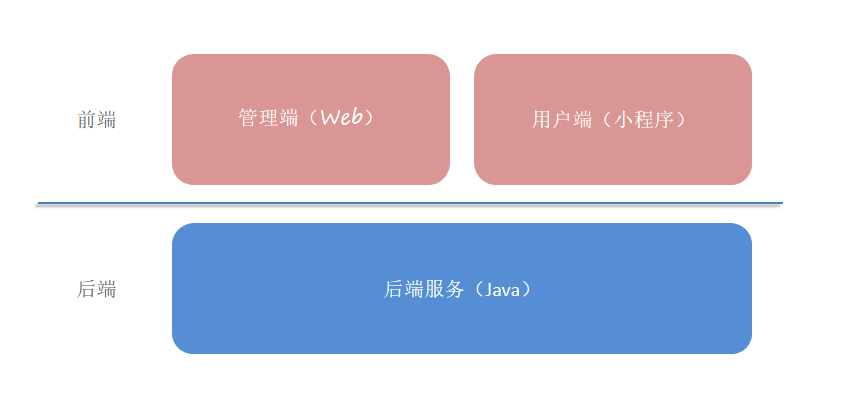

开发环境搭建主要包含**前端环境**和**后端环境**两部分。作为服务端开发工程师， 我们课程学习的重心应该放在后端的业务代码上， 前端的页面我们只需要导入资料中的nginx， 前端页面的代码我们只需要能看懂即可。


### 3.1 前端环境搭建

> **PPT对照：** 第23—25页。

**1). 前端工程基于 nginx** 

从资料中找到前端运行环境的nginx，移动到**非中文目录**下。

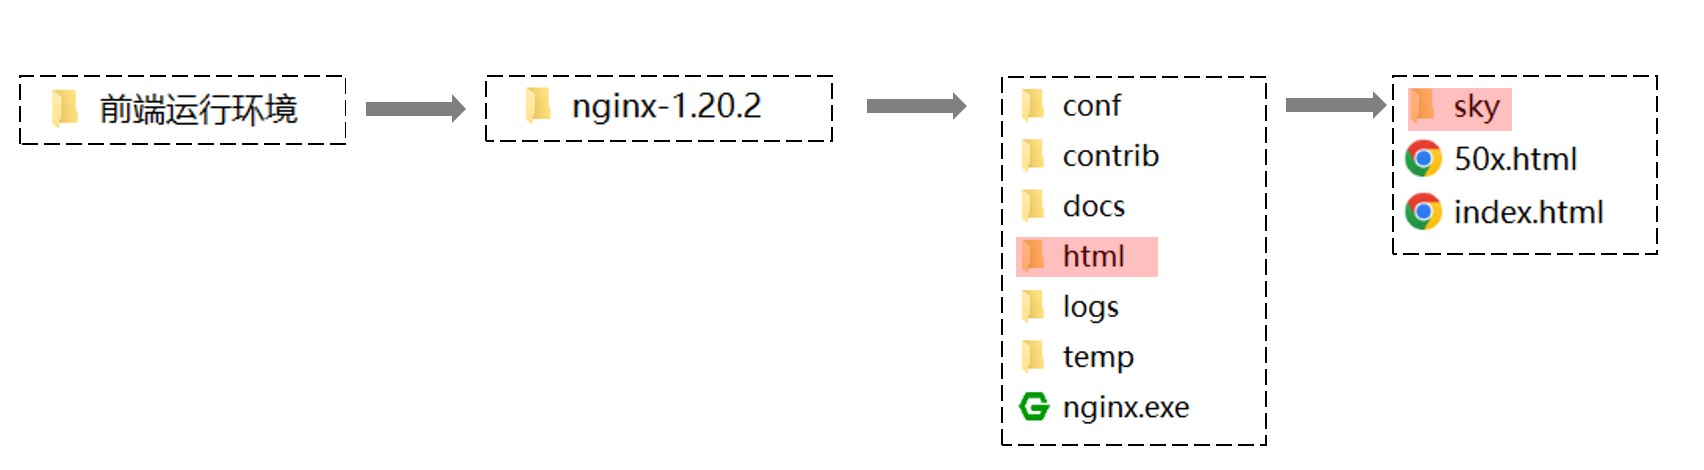

**sky**目录中存放了管理端的前端资源，具体如下：

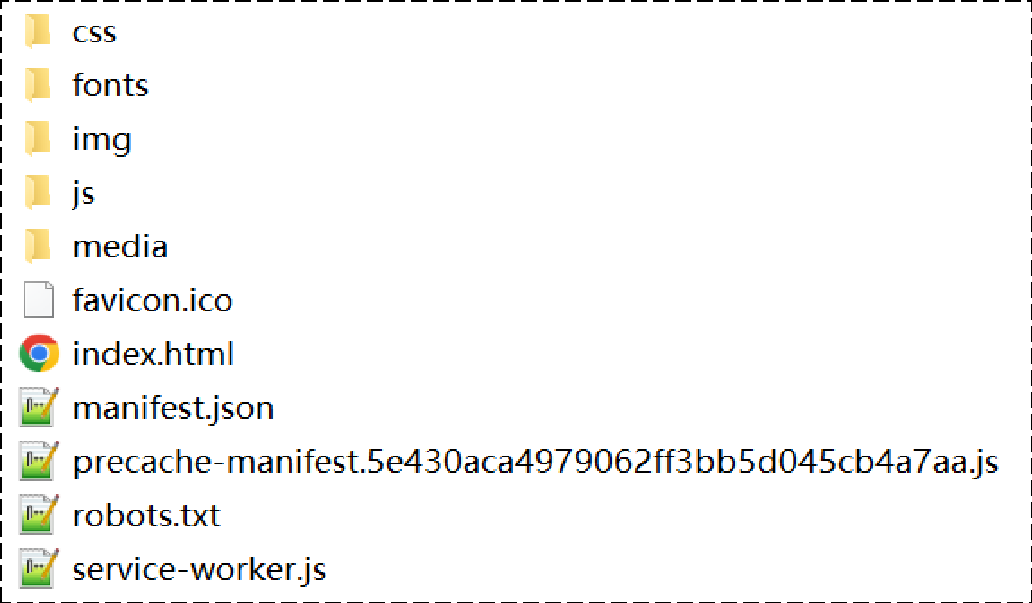

**2). 启动nginx，访问测试** 

双击 nginx.exe 即可启动 nginx 服务，访问端口号为 80

http://localhost:80

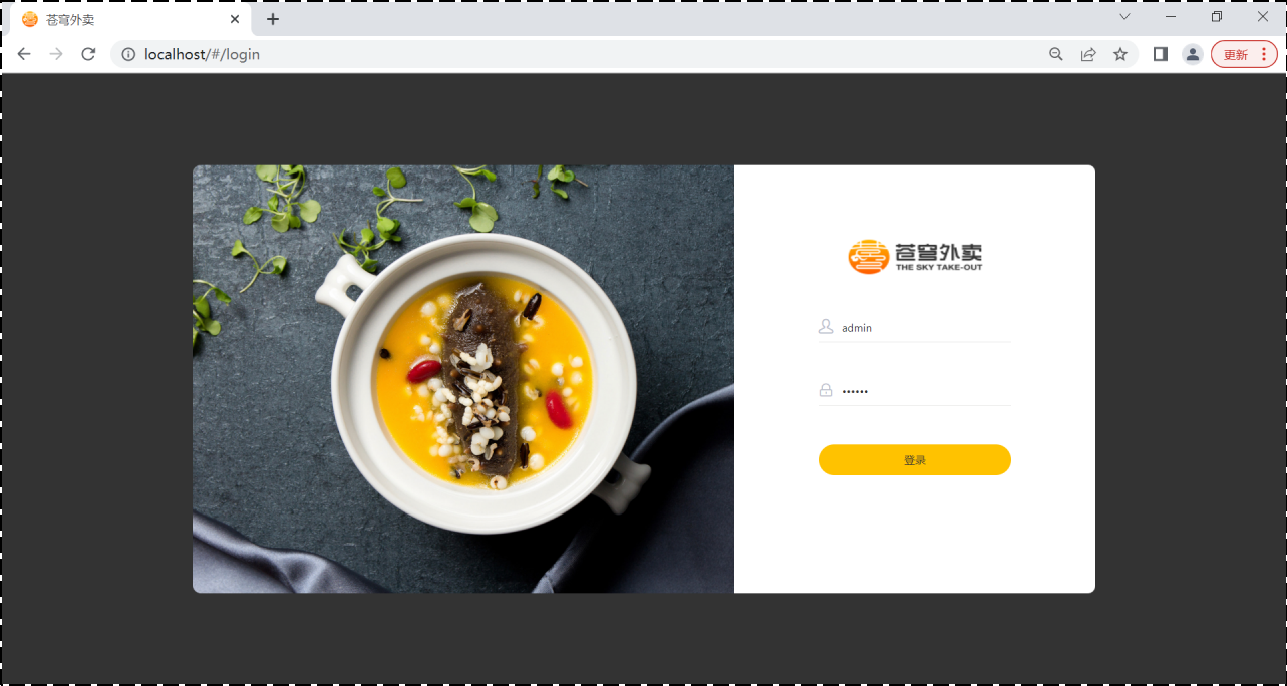


### Nginx 最小操作闭环（补充）

在课程 Nginx 解压目录打开终端。以下是操作示例，不会自动启动你电脑上的服务。

```powershell
# 必须先进入自己的 nginx 解压目录
.
ginx.exe -t
Start-Process -FilePath .
ginx.exe -WindowStyle Hidden

# 修改配置并通过语法检查后，重新加载
.
ginx.exe -t
.
ginx.exe -s reload

# 需要结束练习时，平滑停止
.
ginx.exe -s quit
```

访问首页只证明静态资源能加载，还需要提交一次登录请求验证后端。若80端口占用，先定位已有监听进程，再决定修改 `listen`；例如改成8088后，浏览器入口也应使用 `http://localhost:8088/`。

```powershell
Get-NetTCPConnection -State Listen -LocalPort 80,8080 -ErrorAction SilentlyContinue
```

看到 Nginx 默认欢迎页时检查 `root` / `index` 是否指向课程管理端资源。启动失败时检查 `logs/error.log`、工作目录和端口。


### 3.2 后端环境搭建

> **PPT对照：** 第27—40页。

#### 3.2.1 熟悉项目结构

后端工程基于 maven 进行项目构建，并且进行分模块开发。

**1). 从当天资料中找到后端初始工程：**

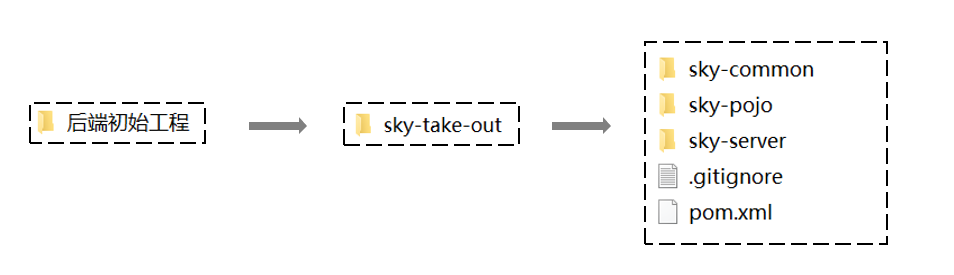

**2). 用 IDEA 打开初始工程，了解项目的整体结构：**

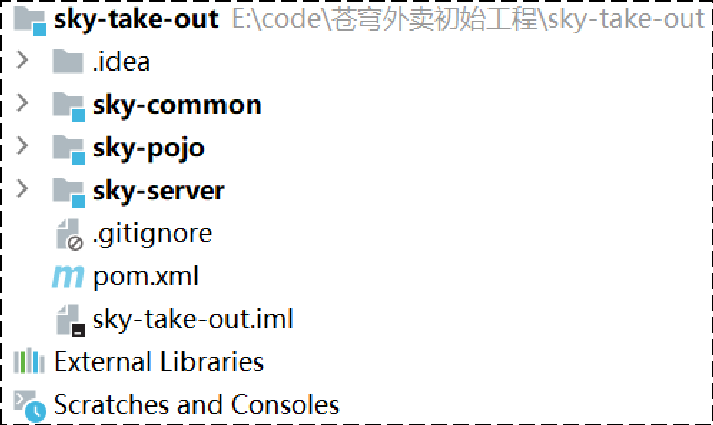

对工程的每个模块作用说明：

| **序号** | **名称**     | **说明**                                                     |
| -------- | ------------ | ------------------------------------------------------------ |
| 1        | sky-take-out | maven父工程，统一管理依赖版本，聚合其他子模块                |
| 2        | sky-common   | 子模块，存放公共类，例如：工具类、常量类、异常类等           |
| 3        | sky-pojo     | 子模块，存放实体类、VO、DTO等                                |
| 4        | sky-server   | 子模块，后端服务，存放配置文件、Controller、Service、Mapper等 |

对项目整体结构了解后，接下来我们详细分析上述的每个子模块：


- **sky-common:** 模块中存放的是一些公共类，可以供其他模块使用

  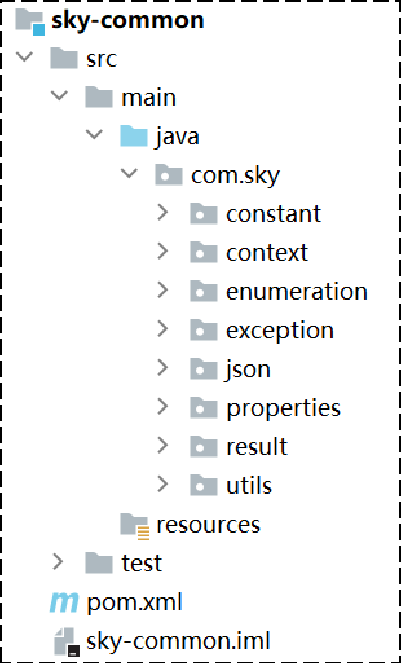

  

  分析sky-common模块的每个包的作用：

  | 名称        | 说明                           |
  | ----------- | ------------------------------ |
  | constant    | 存放相关常量类                 |
  | context     | 存放上下文类                   |
  | enumeration | 项目的枚举类存储               |
  | exception   | 存放自定义异常类               |
  | json        | 处理json转换的类               |
  | properties  | 存放SpringBoot相关的配置属性类 |
  | result      | 返回结果类的封装               |
  | utils       | 常用工具类                     |

  

- **sky-pojo:** 模块中存放的是一些 entity、DTO、VO

  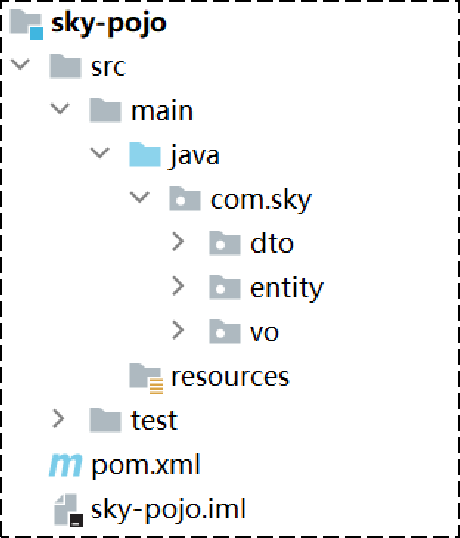

  分析sky-pojo模块的每个包的作用：

  | **名称** | **说明**                                     |
  | -------- | -------------------------------------------- |
  | Entity   | 实体，通常和数据库中的表对应                 |
  | DTO      | 数据传输对象，通常用于程序中各层之间传递数据 |
  | VO       | 视图对象，为前端展示数据提供的对象           |
  | POJO     | 普通Java对象，只有属性和对应的getter和setter |

  

- **sky-server:** 模块中存放的是 配置文件、配置类、拦截器、controller、service、mapper、启动类等

  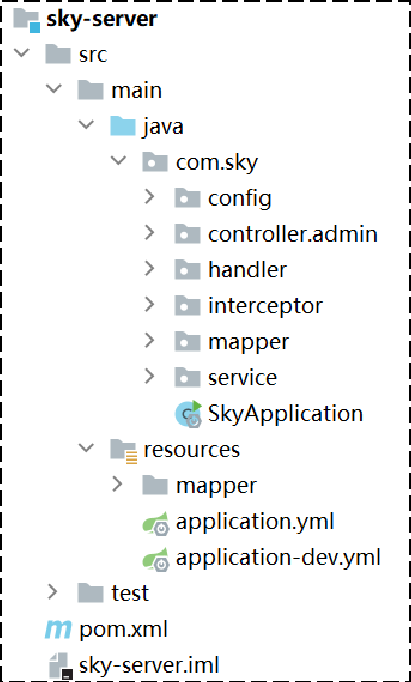

  分析sky-server模块的每个包的作用：

  | 名称           | 说明             |
  | -------------- | ---------------- |
  | config         | 存放配置类       |
  | controller     | 存放controller类 |
  | interceptor    | 存放拦截器类     |
  | mapper         | 存放mapper接口   |
  | service        | 存放service类    |
  | SkyApplication | 启动类           |


#### 3.2.2 Git版本控制

使用Git进行项目代码的版本控制，具体操作：

**1). 创建Git本地仓库**

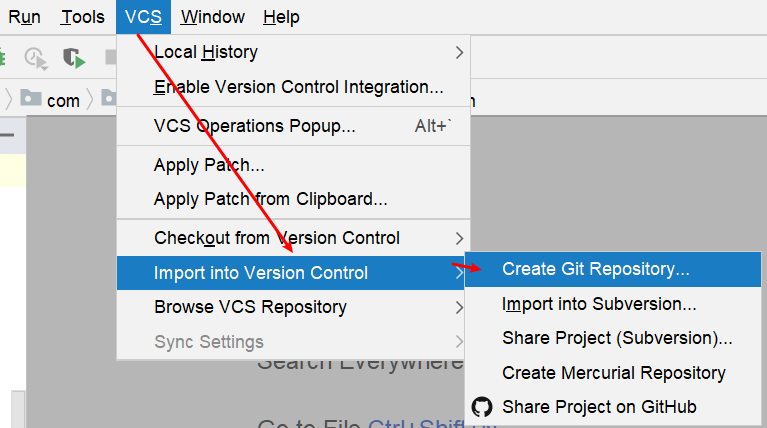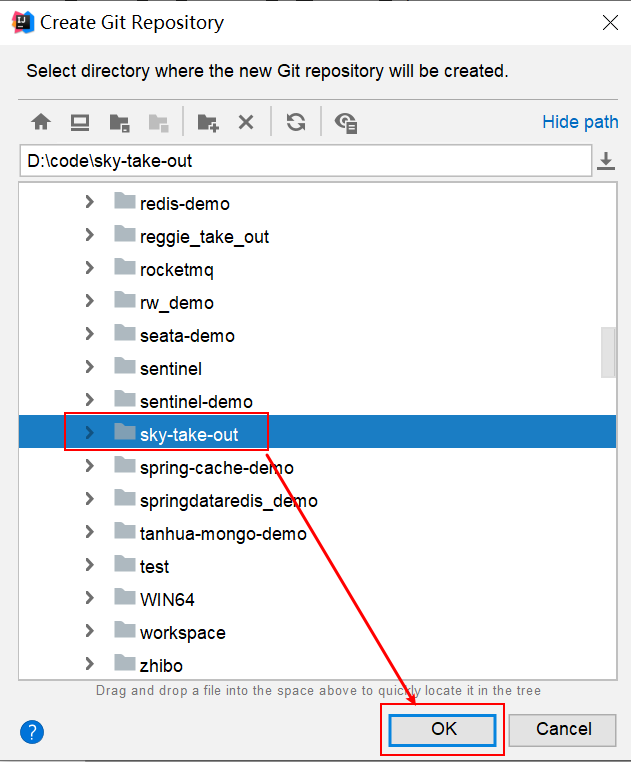


当Idea中出现：

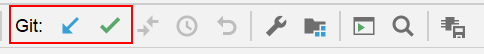

说明本地仓库创建成功。


**2). 创建Git远程仓库**

访问https://gitee.com/，新建仓库

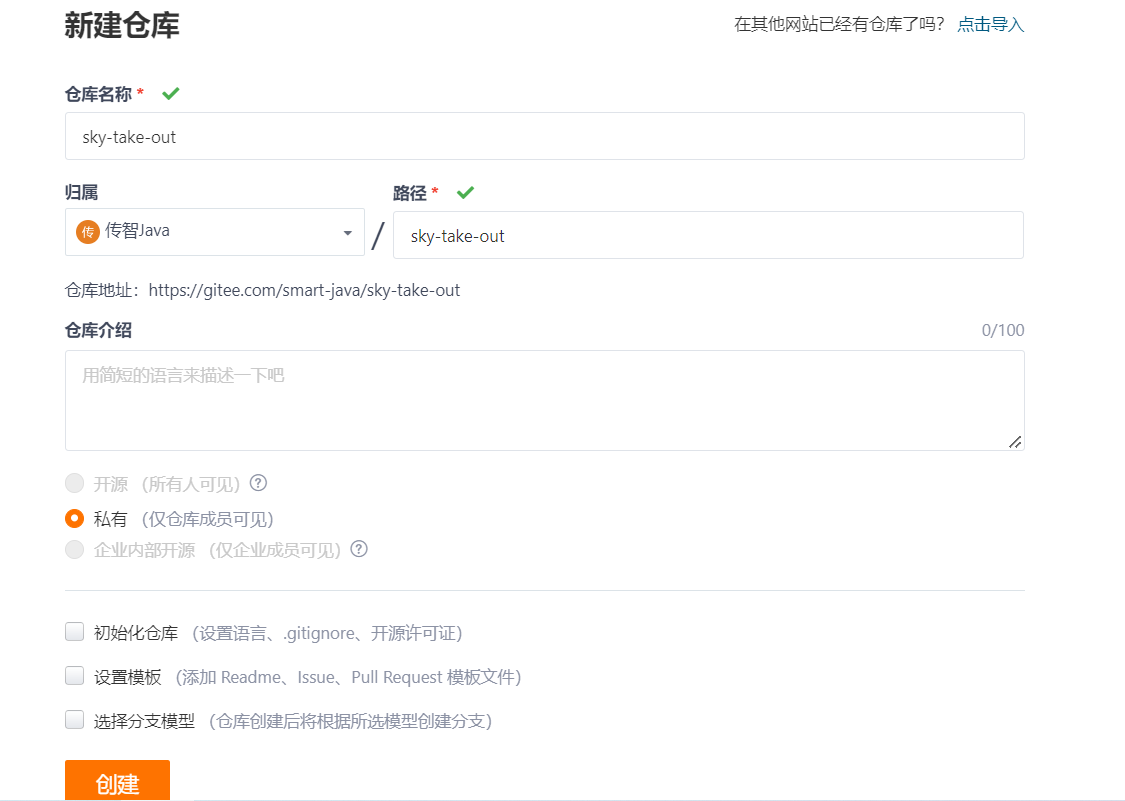

点击 创建 

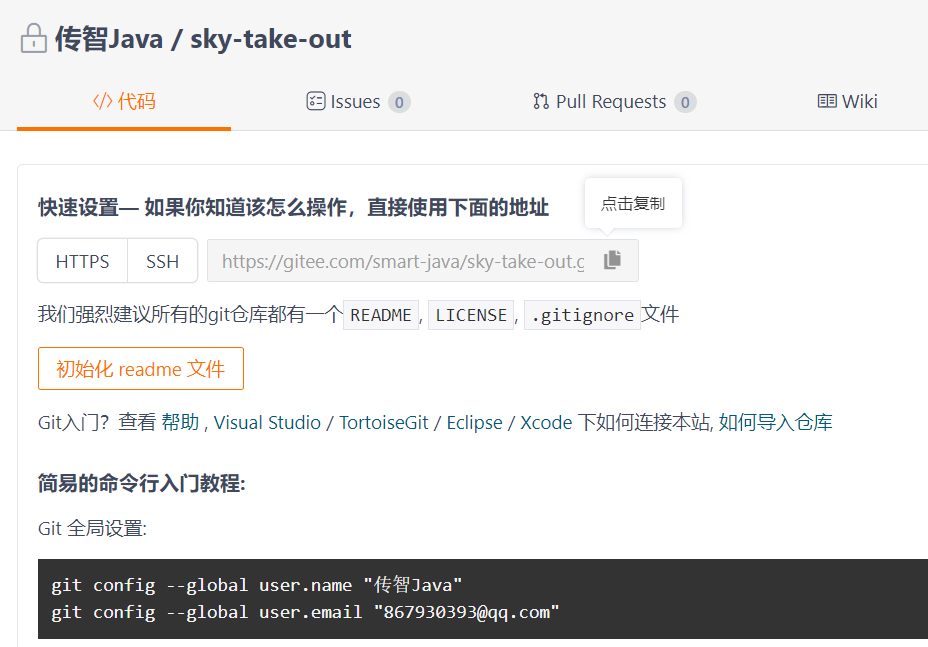


**3). 将本地文件推送到Git远程仓库**


1. **提交文件至本地仓库**

   忽略以下类型文件

   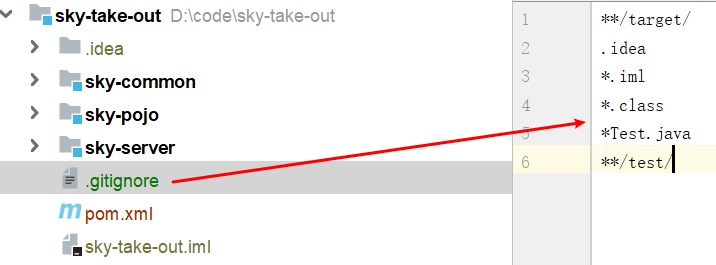

   开始提交

   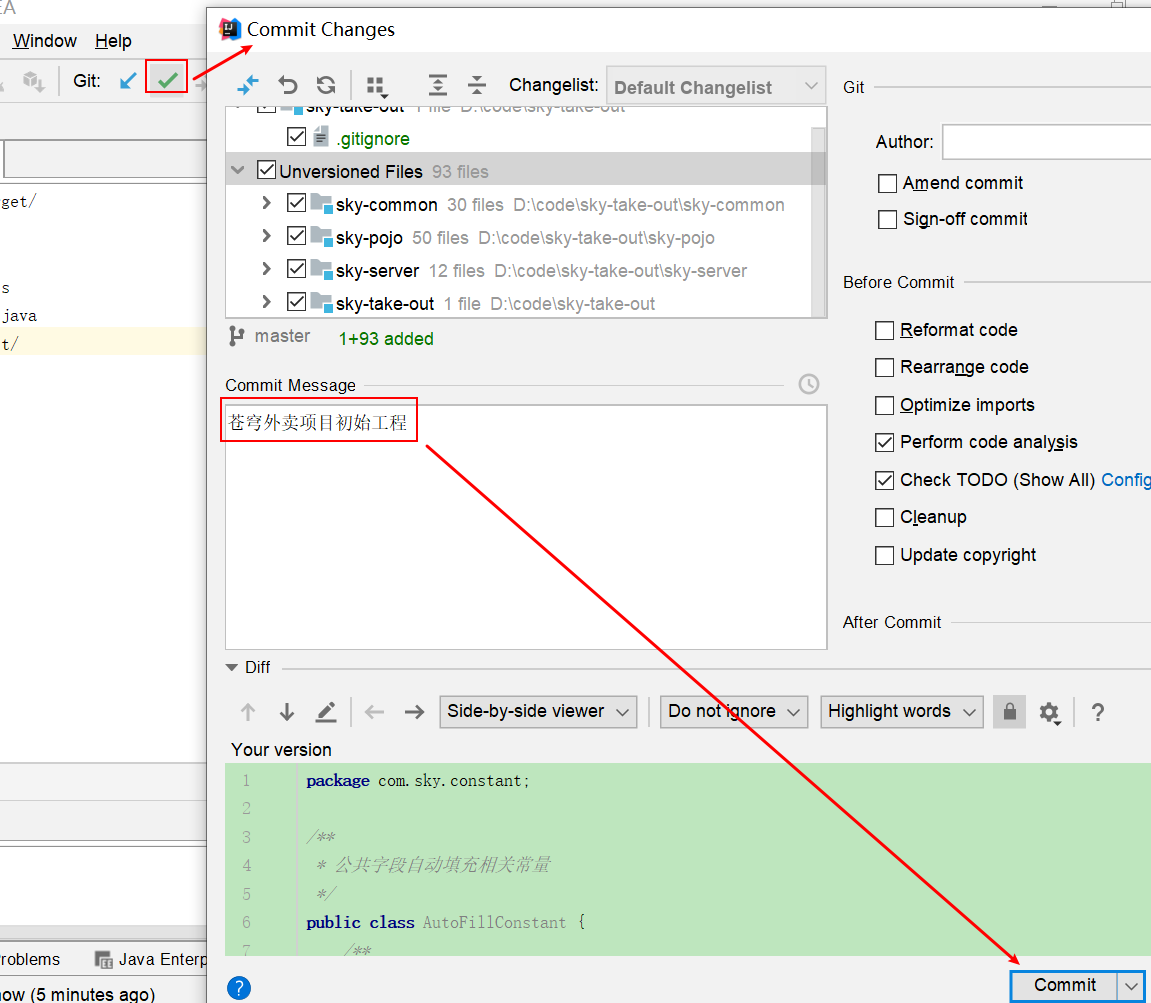

   中间出现：点击commit

   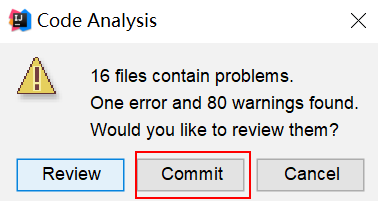

2. **添加Git远程仓库地址**

   复制远程地址：

   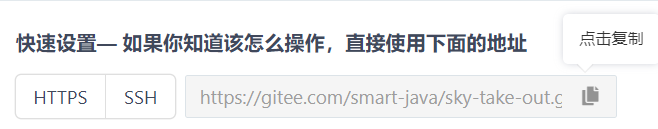

   添加地址：

   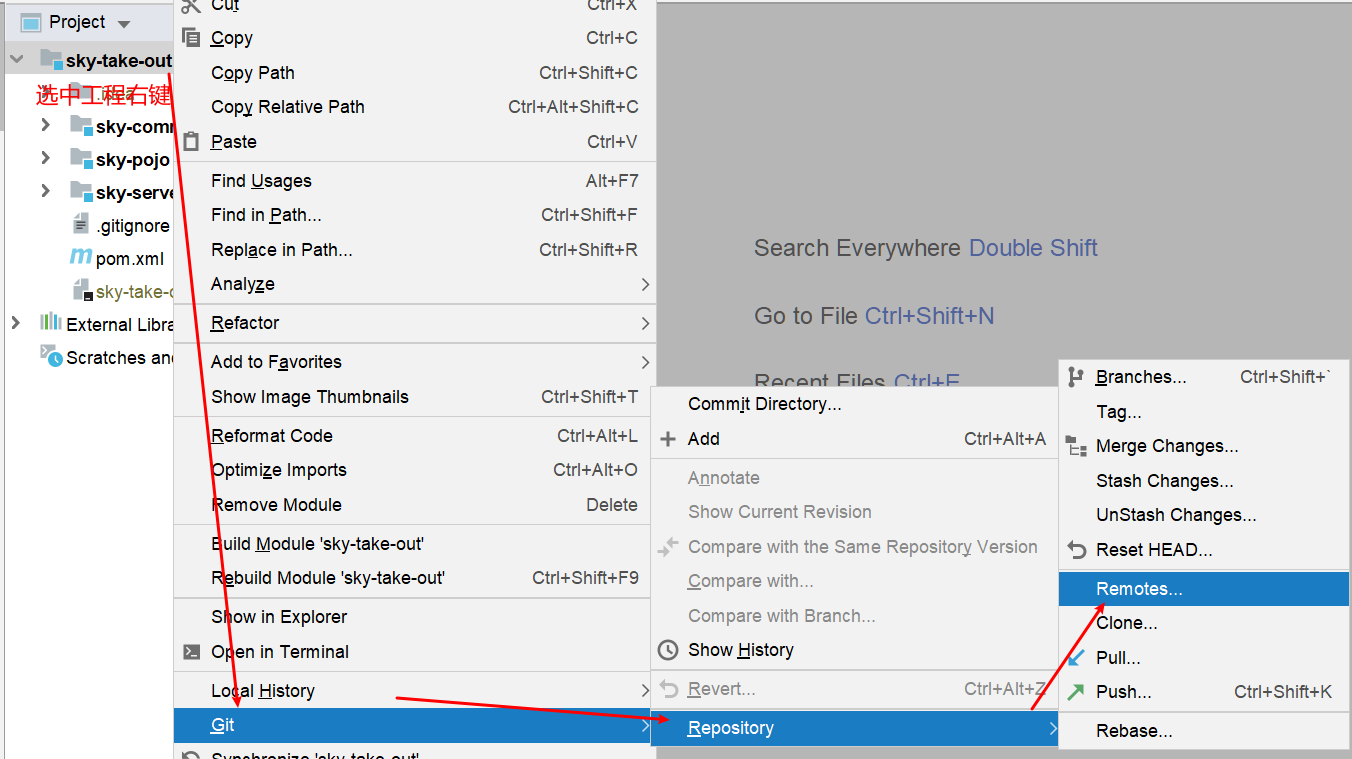

   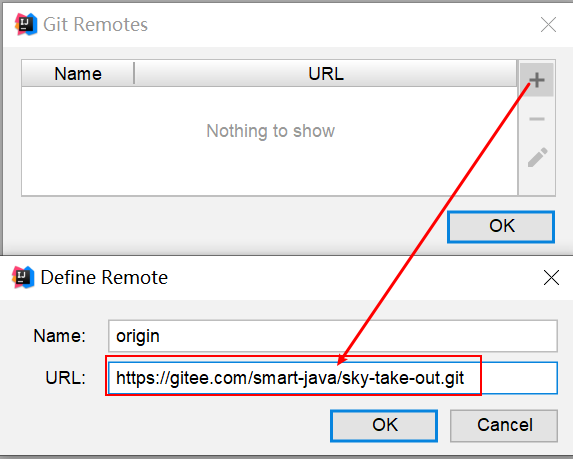

3. **推送**

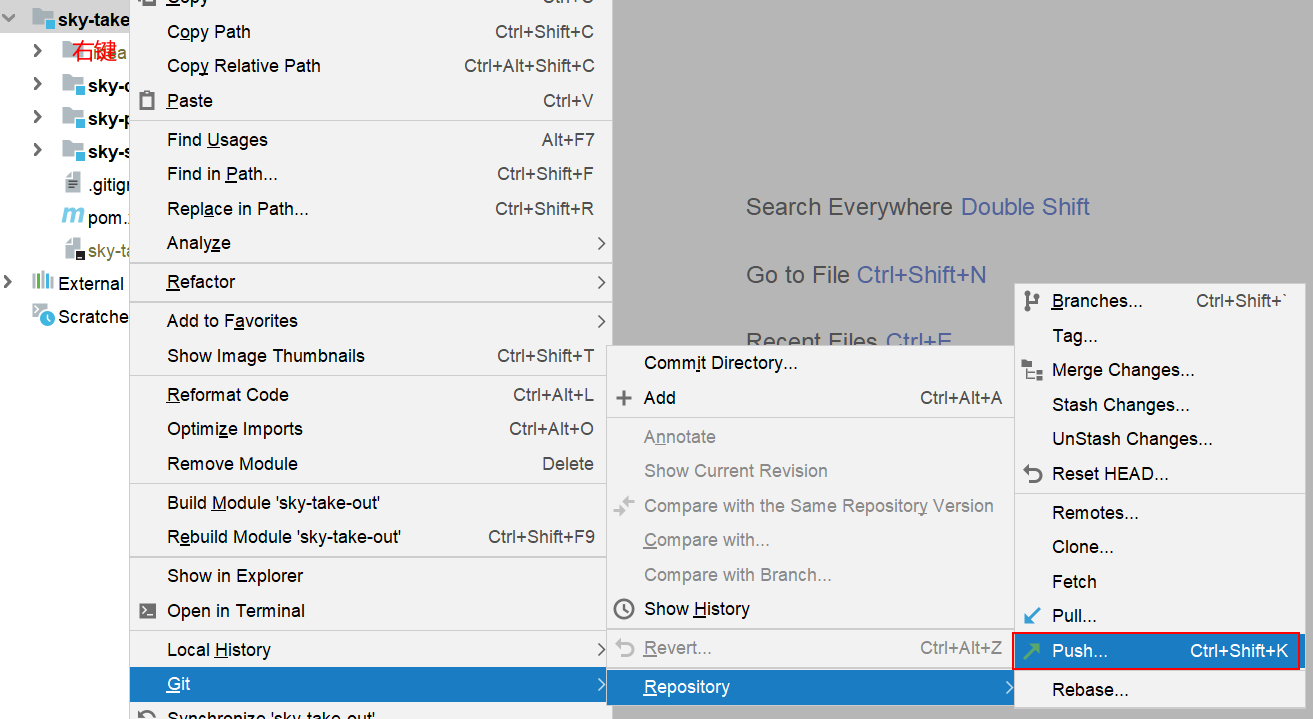

成功推送至远程仓库

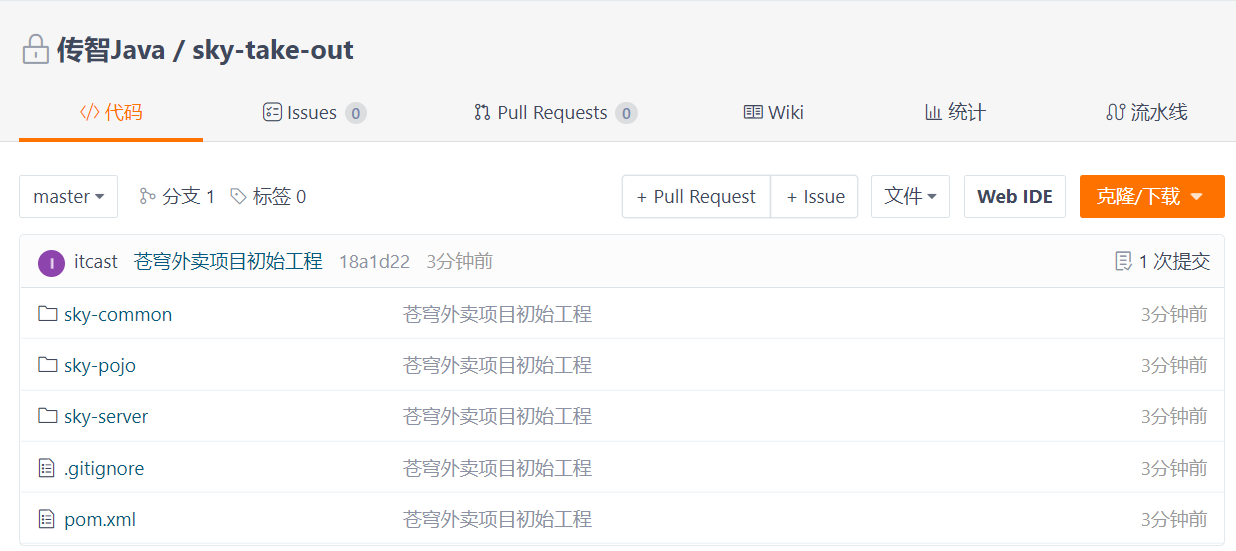


#### 3.2.3 数据库环境搭建

1. **从资料中找到sky.sql**

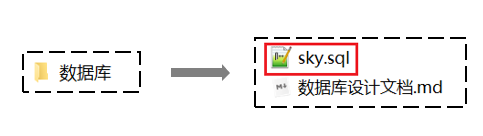

直接打开sky.sql文件

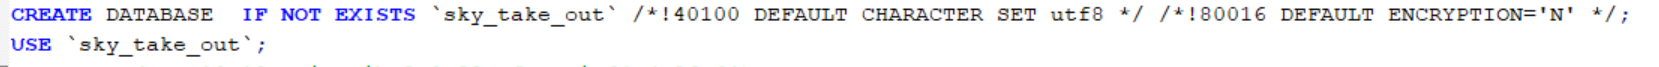

通过该sql文件直接可创建数据库，所以不需要提前创建数据库，直接导入该文件执行即可。

2. **执行sky.sql文件**

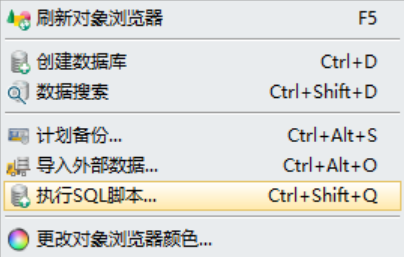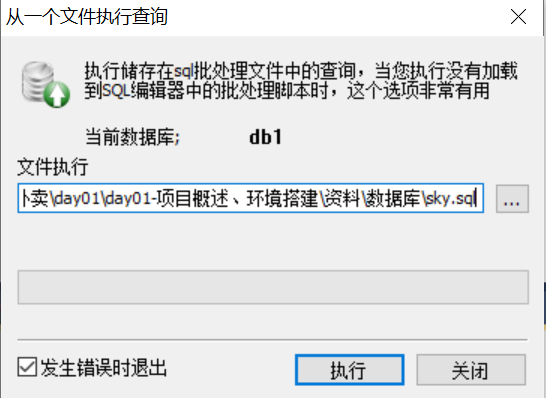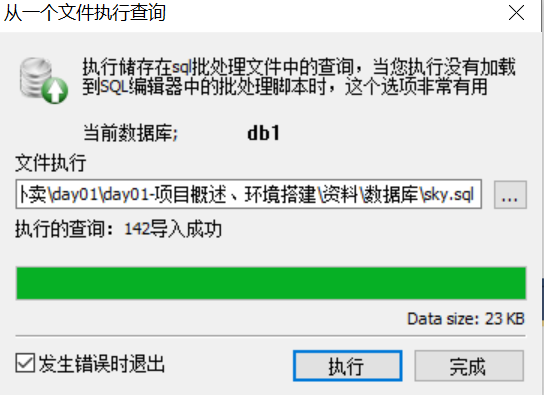

执行完成后，共创建出11张表

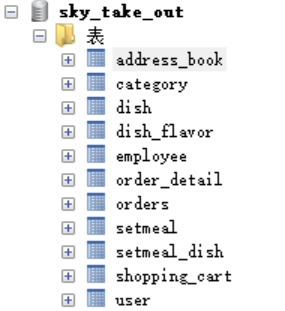

每张表的说明：

| **序号** | **表名**      | **中文名**     |
| -------- | ------------- | -------------- |
| 1        | employee      | 员工表         |
| 2        | category      | 分类表         |
| 3        | dish          | 菜品表         |
| 4        | dish_flavor   | 菜品口味表     |
| 5        | setmeal       | 套餐表         |
| 6        | setmeal_dish  | 套餐菜品关系表 |
| 7        | user          | 用户表         |
| 8        | address_book  | 地址表         |
| 9        | shopping_cart | 购物车表       |
| 10       | orders        | 订单表         |
| 11       | order_detail  | 订单明细表     |

我们目前先简单了解大概有哪些表, 每张表存储什么数据, 有一个印象。对于具体的表结构, 以及表结构中的字段, 可以参考资料中的**《数据库设计文档》**，同时在讲解具体的功能开发时, 我们也会再详细介绍。

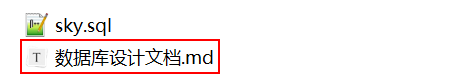


#### 3.2.4 前后端联调

后端的初始工程中已经实现了**登录**功能，直接进行前后端联调测试即可

实现思路：

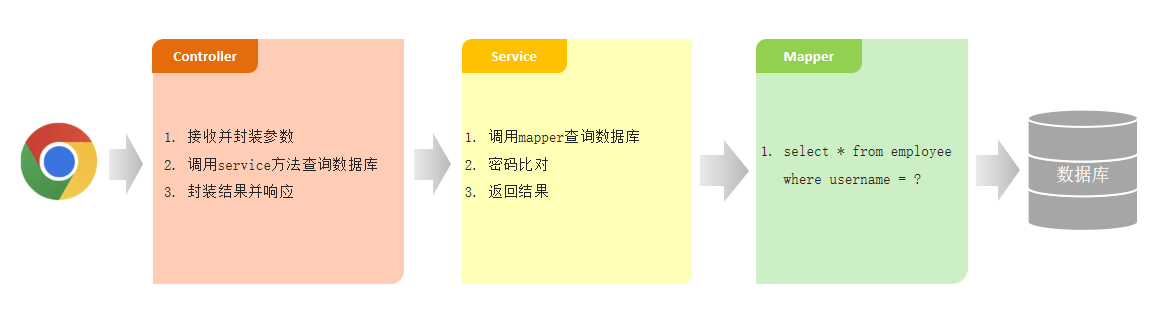

**1.Controller层**

在sky-server模块中，com.sky.controller.admin.EmployeeController

```java
/**
     * 登录
     *
     * @param employeeLoginDTO
     * @return
     */
    @PostMapping("/login")
    public Result<EmployeeLoginVO> login(@RequestBody EmployeeLoginDTO employeeLoginDTO) {
        log.info("员工登录：{}", employeeLoginDTO);
		//调用service方法查询数据库
        Employee employee = employeeService.login(employeeLoginDTO);

        //登录成功后，生成jwt令牌
        Map<String, Object> claims = new HashMap<>();
        claims.put(JwtClaimsConstant.EMP_ID, employee.getId());
        String token = JwtUtil.createJWT(
                jwtProperties.getAdminSecretKey(),
                jwtProperties.getAdminTtl(),
                claims);

        EmployeeLoginVO employeeLoginVO = EmployeeLoginVO.builder()
                .id(employee.getId())
                .userName(employee.getUsername())
                .name(employee.getName())
                .token(token)
                .build();

        return Result.success(employeeLoginVO);
    }
```

**2.Service层**

在sky-server模块中，com.sky.service.impl.EmployeeServiceImpl

```java
/**
     * 员工登录
     *
     * @param employeeLoginDTO
     * @return
     */
    public Employee login(EmployeeLoginDTO employeeLoginDTO) {
        String username = employeeLoginDTO.getUsername();
        String password = employeeLoginDTO.getPassword();

        //1、根据用户名查询数据库中的数据
        Employee employee = employeeMapper.getByUsername(username);

        //2、处理各种异常情况（用户名不存在、密码不对、账号被锁定）
        if (employee == null) {
            //账号不存在
            throw new AccountNotFoundException(MessageConstant.ACCOUNT_NOT_FOUND);
        }

        //密码比对
        if (!password.equals(employee.getPassword())) {
            //密码错误
            throw new PasswordErrorException(MessageConstant.PASSWORD_ERROR);
        }

        if (employee.getStatus() == StatusConstant.DISABLE) {
            //账号被锁定
            throw new AccountLockedException(MessageConstant.ACCOUNT_LOCKED);
        }

        //3、返回实体对象
        return employee;
    }
```

**3.Mapper层**

在sky-server模块中，com.sky.mapper.EmployeeMapper

```java
package com.sky.mapper;

import com.sky.entity.Employee;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Select;

@Mapper
public interface EmployeeMapper {

    /**
     * 根据用户名查询员工
     * @param username
     * @return
     */
    @Select("select * from employee where username = #{username}")
    Employee getByUsername(String username);

}

```

注：可以通过断点调试跟踪后端程序的执行过程


#### 3.2.5 nginx反向代理和负载均衡

对登录功能测试完毕后，接下来，我们思考一个问题：**前端发送的请求，是如何请求到后端服务的？**

前端请求地址：http://localhost/api/employee/login

后端接口地址：http://localhost:8080/admin/employee/login


              **前端请求地址**                                                                                       **后端接口地址**

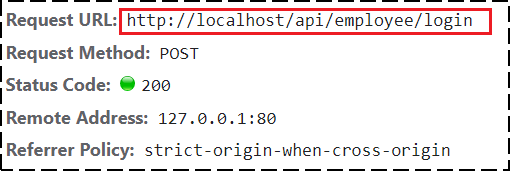                                  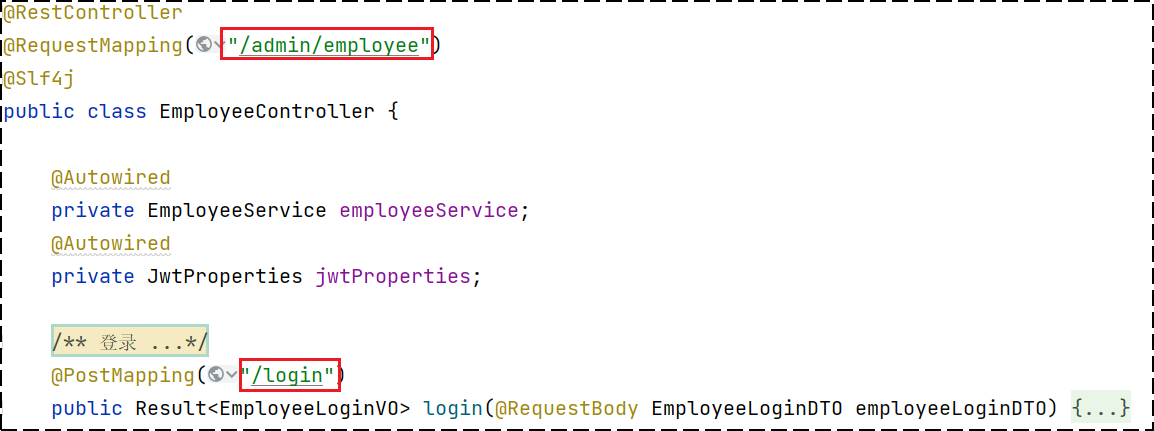

很明显，两个地址不一致，那是如何请求到后端服务的呢？

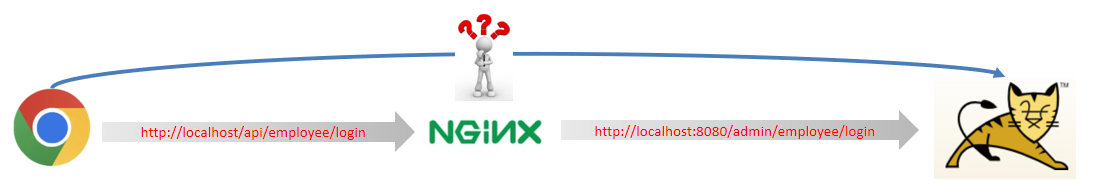


**1). nginx反向代理**

**nginx 反向代理**，就是将前端发送的动态请求由 nginx 转发到后端服务器

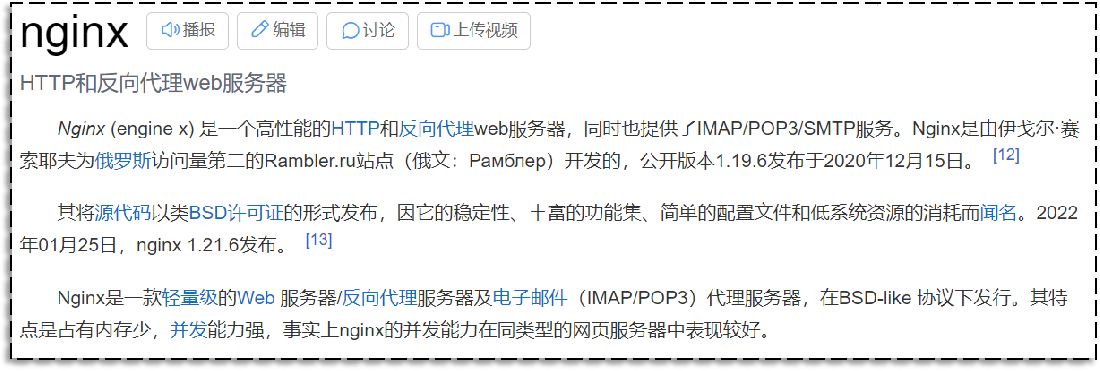

那为什么不直接通过浏览器直接请求后台服务端，需要通过nginx反向代理呢？


**nginx 反向代理的好处：**

- 提高访问速度

  因为nginx本身可以进行缓存，如果访问的同一接口，并且做了数据缓存，nginx就直接可把数据返回，不需要真正地访问服务端，从而提高访问速度。

- 进行负载均衡

  所谓负载均衡,就是把大量的请求按照我们指定的方式均衡的分配给集群中的每台服务器。

- 保证后端服务安全

  因为一般后台服务地址不会暴露，所以使用浏览器不能直接访问，可以把nginx作为请求访问的入口，请求到达nginx后转发到具体的服务中，从而保证后端服务的安全。

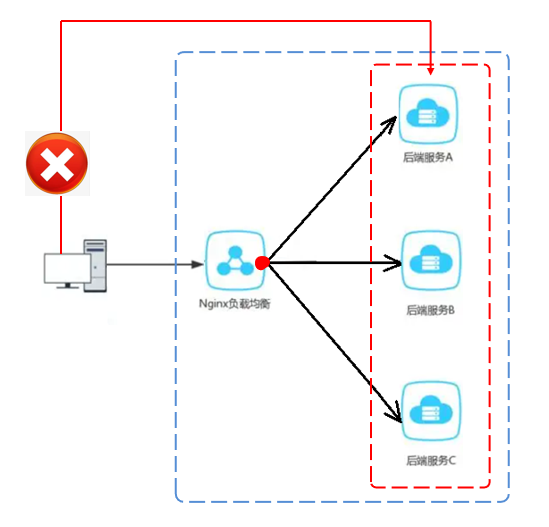

**nginx 反向代理的配置方式：**

```nginx
server{
    listen 80;
    server_name localhost;
    
    location /api/{
        proxy_pass http://localhost:8080/admin/; #反向代理
    }
}
```

**proxy_pass：**该指令是用来设置代理服务器的地址，可以是主机名称，IP地址加端口号等形式。

如上代码的含义是：监听80端口号， 然后当我们访问 http://localhost:80/api/../..这样的接口的时候，它会通过 location /api/ {} 这样的反向代理到 http://localhost:8080/admin/上来。


接下来，进到nginx-1.20.2\conf，打开nginx配置

```nginx
# 反向代理,处理管理端发送的请求
location /api/ {
	proxy_pass   http://localhost:8080/admin/;
    #proxy_pass   http://webservers/admin/;
}
```

当在访问http://localhost/api/employee/login，nginx接收到请求后转到http://localhost:8080/admin/，故最终的请求地址为http://localhost:8080/admin/employee/login，和后台服务的访问地址一致。


**2). nginx 负载均衡**

当如果服务以集群的方式进行部署时，那nginx在转发请求到服务器时就需要做相应的负载均衡。其实，负载均衡从本质上来说也是基于反向代理来实现的，最终都是转发请求。


**nginx 负载均衡的配置方式：**

```nginx
upstream webservers{
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
server{
    listen 80;
    server_name localhost;
    
    location /api/{
        proxy_pass http://webservers/admin;#负载均衡
    }
}
```

**upstream：**如果代理服务器是一组服务器的话，我们可以使用upstream指令配置后端服务器组。

如上代码的含义是：监听80端口号， 然后当我们访问 http://localhost:80/api/../..这样的接口的时候，它会通过 location /api/ {} 这样的反向代理到 http://webservers/admin，根据webservers名称找到一组服务器，根据设置的负载均衡策略(默认是轮询)转发到具体的服务器。

**注：**upstream后面的名称可自定义，但要上下保持一致。


**nginx 负载均衡策略：**

| **名称**   | **说明**                                               |
| ---------- | ------------------------------------------------------ |
| 轮询       | 默认方式                                               |
| weight     | 权重方式，默认为1，权重越高，被分配的客户端请求就越多  |
| ip_hash    | 依据ip分配方式，这样每个访客可以固定访问一个后端服务   |
| least_conn | 依据最少连接方式，把请求优先分配给连接数少的后端服务   |
| url_hash   | 依据url分配方式，这样相同的url会被分配到同一个后端服务 |
| fair       | 依据响应时间方式，响应时间短的服务将会被优先分配       |

具体配置方式：

**轮询：**

```nginx
upstream webservers{
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
```

**weight:**

```nginx
upstream webservers{
    server 192.168.100.128:8080 weight=90;
    server 192.168.100.129:8080 weight=10;
}
```

**ip_hash:**

```nginx
upstream webservers{
    ip_hash;
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
```

**least_conn:**

```nginx
upstream webservers{
    least_conn;
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
```

**url_hash:**

```nginx
upstream webservers{
    hash &request_uri;
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
```

**fair:**

```nginx
upstream webservers{
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
    fair;
}
```


### 3.2 学习补充：工程、数据库与登录联调

#### Maven模块与分层职责

依赖方向以各模块 POM 为准。典型用法是 `sky-server` 使用 `sky-common` 的公共工具和 `sky-pojo` 的数据对象。父工程聚合模块与管理版本，本身不等于某个可启动服务。启动类位于 `sky-server`，所以应运行 `SkyApplication`。

| 对象或层 | 登录时的作用 | 应避免的做法 |
| --- | --- | --- |
| EmployeeLoginDTO | 接收用户名、密码 | 把请求对象直接当成数据库记录 |
| Employee实体 | 表示查出的员工记录 | 原样把含密码字段的实体返回前端 |
| EmployeeLoginVO | 返回id、用户名、姓名、token | 返回员工密码或密码哈希 |
| Controller | 请求绑定、调用Service、组装响应 | 记录包含密码的整个DTO |
| Service | 用户存在、密码、禁用状态校验 | 在密码错误时仍然签发token |
| Mapper | 用参数查询员工 | 用字符串拼接SQL接收用户输入 |

POJO泛指普通Java对象，DTO、VO、Entity是按用途区分的对象类别。课程“只有属性与getter/setter”的说法是对其数据模型写法的简化。

#### Git起始版本

在业务源码仓库中检查 `.gitignore`，排除生成目录、IDE配置和本地私密配置。不要把下面的命令直接在当前笔记仓库重复执行。

```gitignore
**/target/
.idea/
*.iml
.env
```

一个初始提交应能解释“导入了哪个工程、采用什么版本、怎样启动”。课程展示 Gitee，实际使用哪一个托管平台不影响本地提交、远程地址和推送之间的关系。不要忽略所有 YAML，否则必要的共享配置模板也会遗漏。

#### 数据库与配置核对

讲义 `sky.sql` 截图中的库名是 `sky_take_out`。使用课程SQL导入后，检查表数与员工状态；笔记中不另造一个替代的建表文件。

```sql
SHOW DATABASES;
USE sky_take_out;
SHOW TABLES;
SELECT id, username, status FROM employee;
```

数据库配置应核对主机、端口、库名、用户名、密码及连接参数。配置路径与 profile 写法以实际工程为准。`Access denied` 优先检查账号权限，`Unknown database` 检查库名和导入结果，连接超时先检查数据库进程与端口。

11张表之间的业务关系可先记住：分类下有菜品或套餐，菜品有关联口味，套餐通过 `setmeal_dish` 关联菜品；用户有关联地址、购物车、订单，订单含明细。关系字段和是否建立外键以实际建表SQL为准。

#### 登录请求与断点

浏览器开发者工具 Network 中检查请求方式、JSON、响应状态及业务响应。初始明文比对和后续MD5比对属于两个阶段，数据库内容必须与正在运行的代码一致。

```json
{
  "username": "admin",
  "password": "123456"
}
```

截图对应课程测试账号 `admin / 123456`。仅在自己导入的测试数据仍使用这一账号时适用。

```powershell
# 绕过Nginx，直接定位后端登录接口
$loginBody = @{ username = 'admin'; password = '123456' } | ConvertTo-Json
Invoke-RestMethod -Method Post -Uri 'http://localhost:8080/admin/employee/login' -ContentType 'application/json' -Body $loginBody
```

断点顺序：Controller入口、Service取参数、Mapper查询、密码比对、账号状态判断、JWT签发、响应构建。原代码 `log.info("员工登录：{}", employeeLoginDTO)` 可能把密码输出到日志；练习补充写法应只记录不敏感的用户名。

```java
log.info("员工登录，username={}", employeeLoginDTO.getUsername());
```

JWT成功签发不等于所有接口都已受到保护，还要检查拦截器校验、过期时间和签名密钥。浏览器请求同源 `/api` 时由 Nginx 代理到后端，可避免页面直接跨端口调用接口。

#### Nginx示例勘误

1. **路径末尾的 `/`。** 讲义负载均衡示例写 `proxy_pass http://webservers/admin;`，PPT第39页写 `.../admin/;`。在 `location /api/` 中应采用带末尾斜杠的示例，才会把 `/api/employee/login` 拼成 `/admin/employee/login`。原讲义代码保留，下面给出修正版本。

```nginx
# 放在 nginx.conf 的 http {} 内
upstream webservers {
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}

server {
    listen 80;
    server_name localhost;
    location /api/ {
        proxy_pass http://webservers/admin/;
    }
}
```

这里的IP是讲义集群演示地址；单机练习保留 `http://localhost:8080/admin/` 即可。新增 `server` 块前应核对原配置，避免重复定义监听入口。

2. **哈希参数。** 讲义中的 `hash &request_uri;` 应改成 Nginx变量 `$request_uri`。开源Nginx可用内置 `hash` 指令配置URI哈希，不能把表格中的 `url_hash` 当作一定存在的指令。

```nginx
upstream webservers {
    hash $request_uri;
    server 192.168.100.128:8080;
    server 192.168.100.129:8080;
}
```

3. **`fair`兼容性。** `fair` 依赖第三方模块，并非普通开源Nginx默认可用指令。课程若未带该模块，不能直接复制这段配置。`weight` 控制分配比例，`least_conn` 优先选择连接少的实例；请求分配也不保证各服务的业务耗时相等。

4. **代理与安全。** 默认反向代理不会自动缓存每个接口，也不会单独保证后端安全。后端是否允许公网直连，取决于监听地址、防火墙和网络设置；代理之后仍需要认证、授权、HTTPS和合适的日志策略。

修改配置后先 `nginx -t`，通过后 reload。出现502时先验证8080后端是否可达；出现404时对照路径替换、Controller映射和代理目标。


### 3.3 完善登录功能

> **PPT对照：** 第42—44页。

**问题：**员工表中的密码是明文存储，安全性太低。

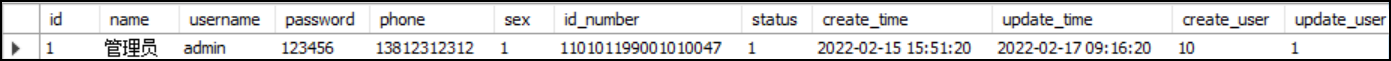

**解决思路：**

1. 将密码加密后存储，提高安全性

   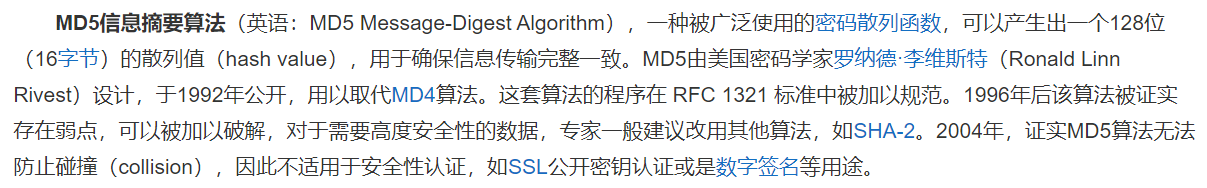

2. 使用MD5加密方式对明文密码加密

   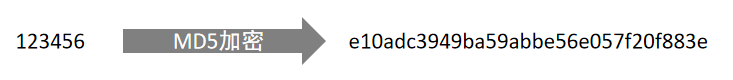

**实现步骤：**

1. 修改数据库中明文密码，改为MD5加密后的密文

   打开employee表，修改密码

   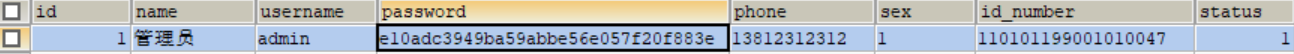

2. 修改Java代码，前端提交的密码进行MD5加密后再跟数据库中密码比对

   打开EmployeeServiceImpl.java，修改比对密码

   ```java
   /**
        * 员工登录
        *
        * @param employeeLoginDTO
        * @return
        */
       public Employee login(EmployeeLoginDTO employeeLoginDTO) {
   
           //1、根据用户名查询数据库中的数据
          
           //2、处理各种异常情况（用户名不存在、密码不对、账号被锁定）
           //.......
           //密码比对
           // TODO 后期需要进行md5加密，然后再进行比对
           password = DigestUtils.md5DigestAsHex(password.getBytes());
           if (!password.equals(employee.getPassword())) {
               //密码错误
               throw new PasswordErrorException(MessageConstant.PASSWORD_ERROR);
           }
   
           //........
   
           //3、返回实体对象
           return employee;
       }
   ```


### MD5用法与课程边界（补充与勘误）

MD5是不可逆哈希算法。课程把它称为“加密”，更准确的说法是计算密码的哈希表示。输入 `123456` 的MD5十六进制结果为 `e10adc3949ba59abbe56e057f20f883e`，与讲义截图一致。

课程练习需要同步修改测试数据库与比对逻辑；只改其中一处会导致正确密码也无法登录。不要把已哈希的值再次当明文计算MD5。

```java
import org.springframework.util.DigestUtils;
import java.nio.charset.StandardCharsets;

// 插入到原Service取到username/password并查出employee之后
password = DigestUtils.md5DigestAsHex(password.getBytes(StandardCharsets.UTF_8));
if (!password.equals(employee.getPassword())) {
    throw new PasswordErrorException(MessageConstant.PASSWORD_ERROR);
}
```

原讲义的完整方法使用 `...` 省略了部分逻辑，不可原样编译。补充片段只展示应修改的比对位置；仍保留用户不存在和账号禁用的检查。生产密码存储通常使用带盐、可调计算成本的密码哈希，例如 BCrypt、Argon2或PBKDF2，配合HTTPS和登录限流。无盐MD5不能作为生产密码存储方案。


## 4. 导入接口文档

> **PPT对照：** 第46—49页。

接下来，就要进入到项目的业务开发了，而我们的开发方式就是基本当前企业主流的前后端分离开发方式，那么这种方式就要求我们之前需要先将接口定义好，这样前后端人员才能并行开发，所以，这个章节就需要将接口文档导入到管理平台，为我们后面业务开发做好准备。其实，在真实的企业开发中，接口设计过程其实是一个非常漫长的过程，可能需要多次开会讨论调整，甚至在开发的过程中才会发现某些接口定义还需要再调整，这种情况其实是非常常见的，但是由于项目时间原因，所以选择一次性导入所有的接口，在开发业务功能过程当中，也会带着大家一起来分析一下对应的接口是怎么确定下来的，为什么要这样定义，从而培养同学们的接口设计能力。


### 4.1 前后端分离开发流程

> **PPT对照：** 第47页。

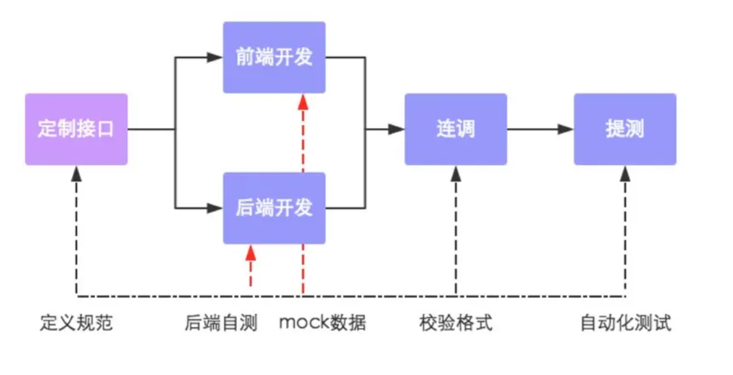

第一步：定义接口，确定接口的路径、请求方式、传入参数、返回参数。

第二步：前端开发人员和后端开发人员并行开发，同时，也可自测。

第三步：前后端人员进行连调测试。

第四步：提交给测试人员进行最终测试。


### 接口约定需要明确什么（补充）

以员工登录为例，应约定 `POST`、后端 `/admin/employee/login`、请求JSON字段、成功响应字段，以及各异常情况下的响应语义。前端看到的 `/api/...` 是代理入口，不能把它与后端 Controller 的路径混为一谈。

还要区分HTTP状态码与 `Result` 中的业务码。实际项目如何使用 `code`、`msg`、`data`，应阅读初始工程的返回类和异常处理器，不自行修改成另一套格式。


### 4.2 操作步骤

> **PPT对照：** 第49页。

将课程资料中提供的项目接口导入YApi。访问地址：http://yapi.smart-xwork.cn/

**1). 从资料中找到项目接口文件**

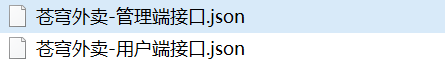

**2). 导入到YApi平台**

在YApi平台创建出两个项目

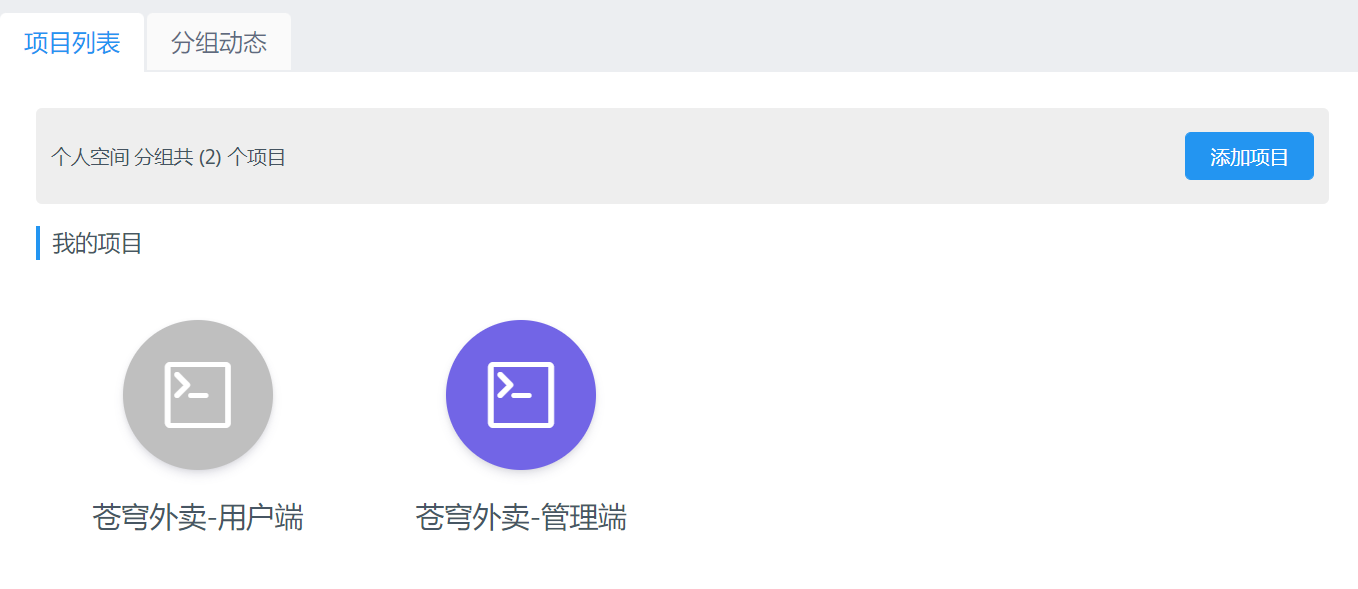

选择苍穹外卖-管理端接口.json导入

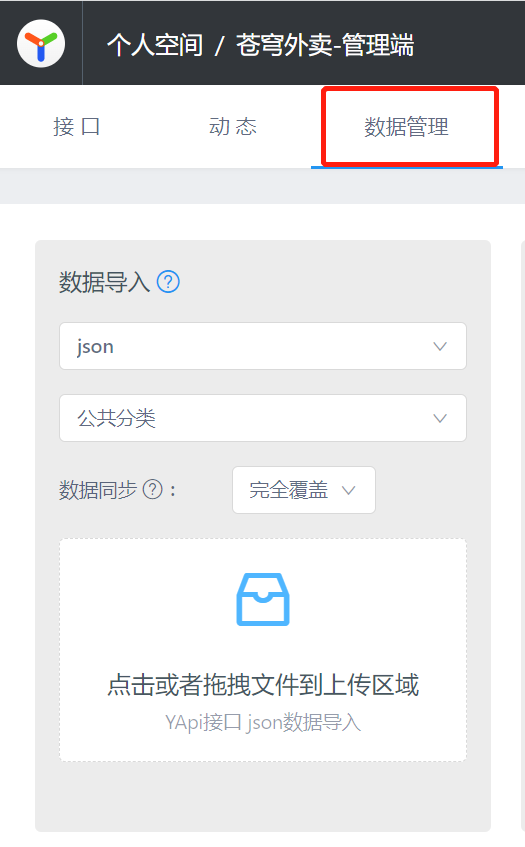

导入成功

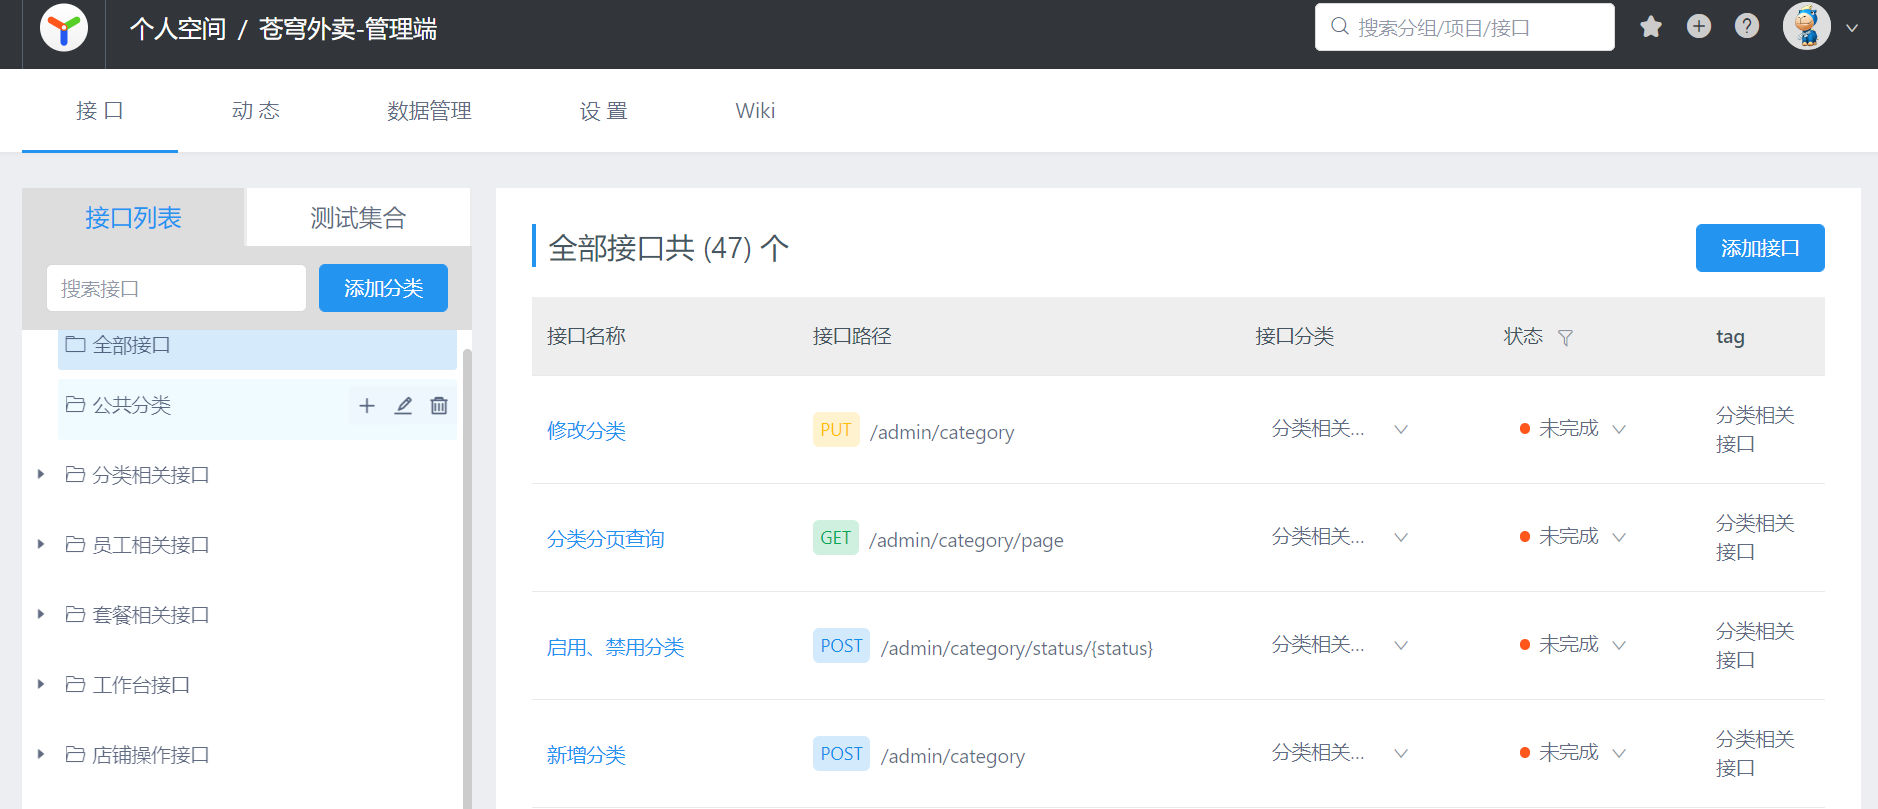


另一个用户端json文件也执行相同操作。


### 接口文件导入的适用范围（补充）

讲义给出的公共YApi地址属于原课程环境，现时可用性未在本次整理中验证。可以使用仍可访问的课程平台、自建YApi，或选择支持对应导入格式的接口工具。先确认JSON的格式再导入，不能假设YApi格式和OpenAPI格式完全互换。

管理端与用户端接口应分别维护，避免把两端的权限、路径与字段混在一起。当前压缩包未包含接口JSON，这部分按课程文件准备好后跟练。


## 5. Swagger

> **PPT对照：** 第51—59页。


### 5.1 介绍

> **PPT对照：** 第52页。

Swagger 是一个规范和完整的框架，用于生成、描述、调用和可视化 RESTful 风格的 Web 服务(<https://swagger.io/>)。 它的主要作用是：

1. 使得前后端分离开发更加方便，有利于团队协作

2. 接口的文档在线自动生成，降低后端开发人员编写接口文档的负担

3. 功能测试 

   Spring已经将Swagger纳入自身的标准，建立了Spring-swagger项目，现在叫Springfox。通过在项目中引入Springfox ，即可非常简单快捷的使用Swagger。

knife4j是为Java MVC框架集成Swagger生成Api文档的增强解决方案,前身是swagger-bootstrap-ui,取名kni4j是希望它能像一把匕首一样小巧,轻量,并且功能强悍!

目前，一般都使用knife4j框架。


### Swagger、Knife4j与接口管理（补充与勘误）

Swagger生态提供接口描述与调试工具，OpenAPI是接口描述规范。课程使用Springfox扫描Controller生成Swagger 2文档，Knife4j提供增强的文档页面。

讲义把Springfox描述为Spring自身的标准项目，这一说法不准确；它是独立的集成库。选择组件时以版本兼容性与维护情况为依据。

| 工具或机制 | 本章的用途 |
| --- | --- |
| YApi等接口管理工具 | 设计阶段维护前后端协作约定 |
| Springfox Docket | 根据实际代码筛选、生成接口文档 |
| Knife4j `/doc.html` | 阅读接口并在线发送调试请求 |

设计文档与生成文档需要核对，防止“约定字段”和“实际返回字段”发生漂移。


### 5.2 使用步骤

> **PPT对照：** 第54—57页。

1. 导入 knife4j 的maven坐标

   在pom.xml中添加依赖

   ```xml
   <dependency>
      <groupId>com.github.xiaoymin</groupId>
      <artifactId>knife4j-spring-boot-starter</artifactId>
   </dependency>
   ```

2. 在配置类中加入 knife4j 相关配置

   WebMvcConfiguration.java

   ```java
   /**
        * 通过knife4j生成接口文档
        * @return
   */
       @Bean
       public Docket docket() {
           ApiInfo apiInfo = new ApiInfoBuilder()
                   .title("苍穹外卖项目接口文档")
                   .version("2.0")
                   .description("苍穹外卖项目接口文档")
                   .build();
           Docket docket = new Docket(DocumentationType.SWAGGER_2)
                   .apiInfo(apiInfo)
                   .select()
                   .apis(RequestHandlerSelectors.basePackage("com.sky.controller"))
                   .paths(PathSelectors.any())
                   .build();
           return docket;
       }
   ```

   

3. 设置静态资源映射，否则接口文档页面无法访问

   WebMvcConfiguration.java

   ```java
   /**
        * 设置静态资源映射
        * @param registry
   */
   protected void addResourceHandlers(ResourceHandlerRegistry registry) {
           registry.addResourceHandler("/doc.html").addResourceLocations("classpath:/META-INF/resources/");
           registry.addResourceHandler("/webjars/**").addResourceLocations("classpath:/META-INF/resources/webjars/");
   }
   ```

4. 访问测试

   接口文档访问路径为 http://ip:port/doc.html ---> http://localhost:8080/doc.html

   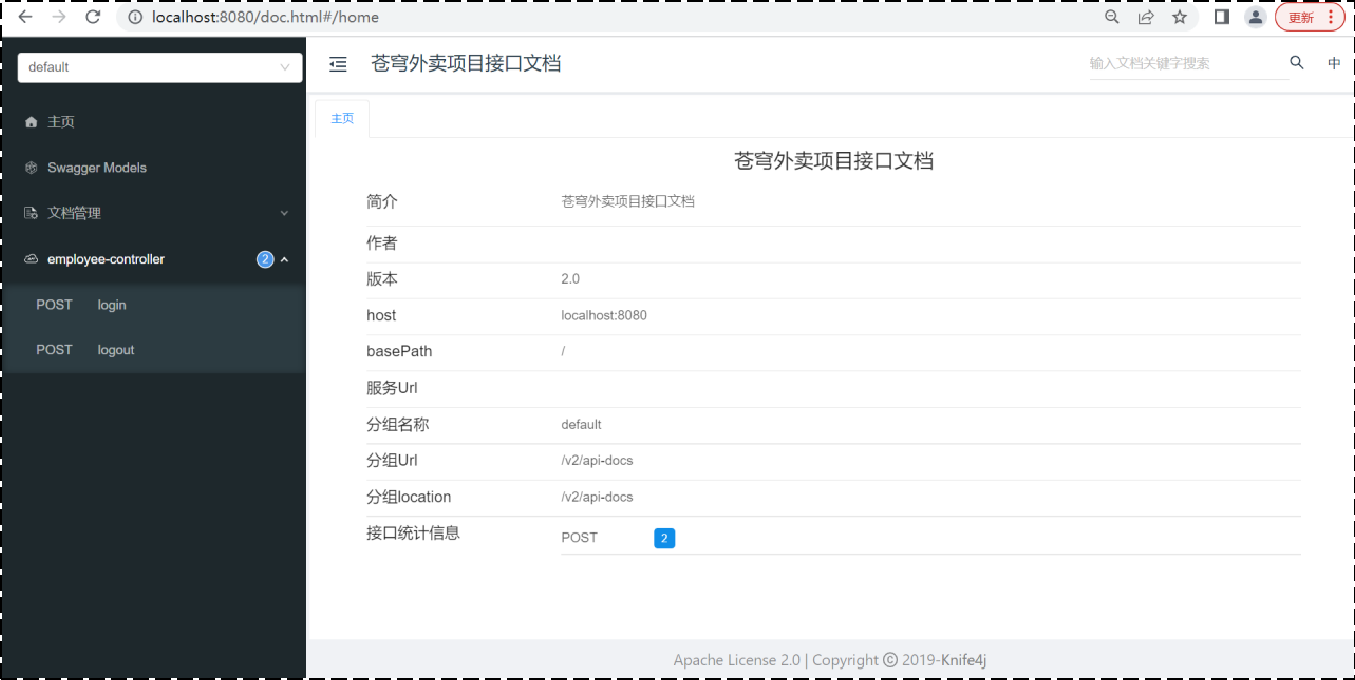

   接口测试:测试登录功能

   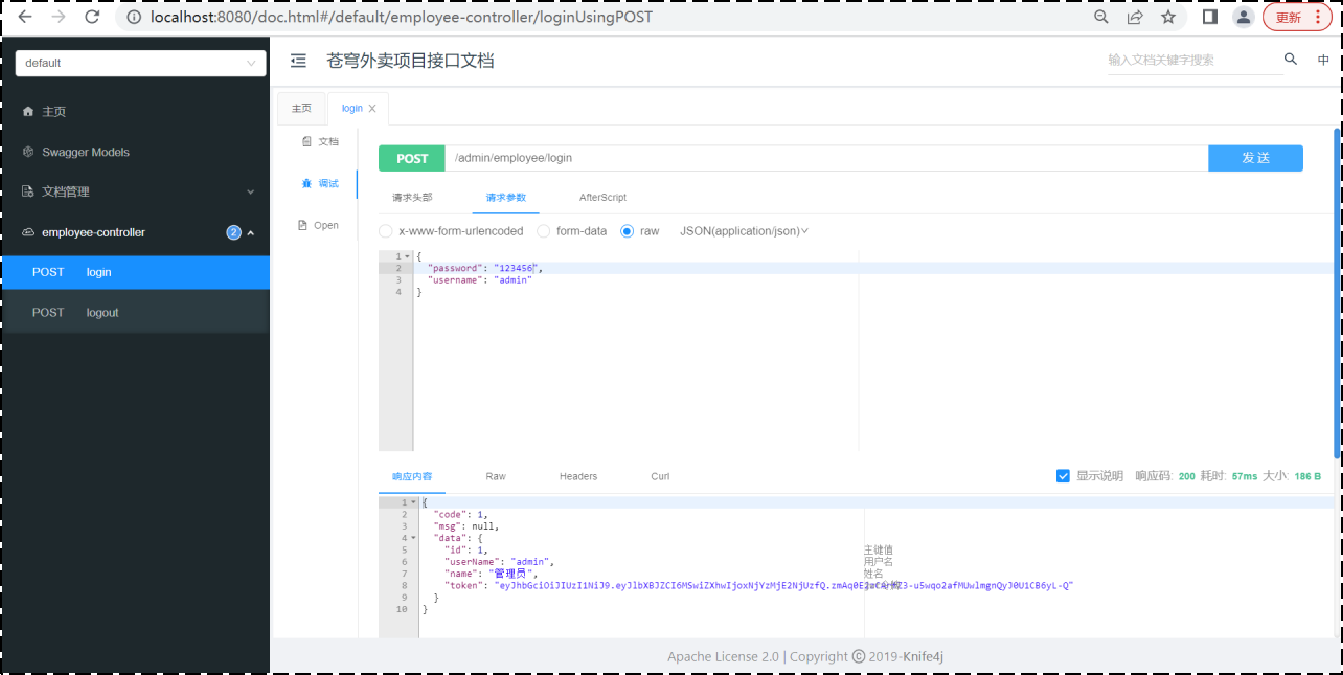

**思考：**通过 Swagger 就可以生成接口文档，那么我们就不需要 Yapi 了？

1、Yapi 是设计阶段使用的工具，管理和维护接口

2、Swagger 在开发阶段使用的框架，帮助后端开发人员做后端的接口测试


### Knife4j配置检查（PPT补充）

PPT第52、54页给出了 `knife4j-spring-boot-starter:3.0.2`。讲义依赖片段省略了版本，通常由父POM管理；若没有统一版本配置，才需要补上明确版本。不要在同一个POM重复添加。

```xml
<!-- 课程Swagger 2路线的坐标示例；按实际父POM版本管理配置 -->
<dependency>
    <groupId>com.github.xiaoymin</groupId>
    <artifactId>knife4j-spring-boot-starter</artifactId>
    <version>3.0.2</version>
</dependency>
```

`Docket`、`ApiInfo`、`ApiInfoBuilder`、`RequestHandlerSelectors`、`PathSelectors` 与 `DocumentationType` 来自 `springfox.documentation` 的对应包。`@Bean` 来自 Spring。检查初始工程已有配置与 imports 后再补入代码。

配置闭环：依赖可解析、`Docket`注册、扫描路径覆盖 `com.sky.controller`、静态资源映射生效、访问 `http://localhost:8080/doc.html`。根路径不加 `/admin`，因为文档资源不是员工Controller的接口。

| 表现 | 优先检查 |
| --- | --- |
| `/doc.html` 返回404 | WebMvc配置是否生效，文档资源映射是否设置 |
| 页面打开但无接口 | Docket注册、扫描包、Controller映射与文档接口是否可达 |
| JS / CSS加载失败 | `/webjars/**`资源映射与访问路径 |
| 启动出现Springfox兼容错误 | Spring Boot、Springfox、Knife4j实际版本组合 |
| 文档中调试受保护接口失败 | 实际拦截器要求的token请求头与令牌有效期 |

这是故障检查顺序，不是已验证你的工程发生了这些问题。不要为了打开页面移除全部鉴权。


### 5.3 常用注解

> **PPT对照：** 第59页。

通过注解可以控制生成的接口文档，使接口文档拥有更好的可读性，常用注解如下：

| **注解**          | **说明**                                               |
| ----------------- | ------------------------------------------------------ |
| @Api              | 用在类上，例如Controller，表示对类的说明               |
| @ApiModel         | 用在类上，例如entity、DTO、VO                          |
| @ApiModelProperty | 用在属性上，描述属性信息                               |
| @ApiOperation     | 用在方法上，例如Controller的方法，说明方法的用途、作用 |

接下来，使用上述注解，生成可读性更好的接口文档

在sky-pojo模块中

EmployeeLoginDTO.java

```java
package com.sky.dto;

import io.swagger.annotations.ApiModel;
import io.swagger.annotations.ApiModelProperty;
import lombok.Data;

import java.io.Serializable;

@Data
@ApiModel(description = "员工登录时传递的数据模型")
public class EmployeeLoginDTO implements Serializable {

    @ApiModelProperty("用户名")
    private String username;

    @ApiModelProperty("密码")
    private String password;

}

```

EmployeeLoginVo.java

```java
package com.sky.vo;

import io.swagger.annotations.ApiModel;
import io.swagger.annotations.ApiModelProperty;
import lombok.AllArgsConstructor;
import lombok.Builder;
import lombok.Data;
import lombok.NoArgsConstructor;

import java.io.Serializable;

@Data
@Builder
@NoArgsConstructor
@AllArgsConstructor
@ApiModel(description = "员工登录返回的数据格式")
public class EmployeeLoginVO implements Serializable {

    @ApiModelProperty("主键值")
    private Long id;

    @ApiModelProperty("用户名")
    private String userName;

    @ApiModelProperty("姓名")
    private String name;

    @ApiModelProperty("jwt令牌")
    private String token;

}
```

在sky-server模块中

EmployeeController.java

```java
package com.sky.controller.admin;

import com.sky.constant.JwtClaimsConstant;
import com.sky.dto.EmployeeLoginDTO;
import com.sky.entity.Employee;
import com.sky.properties.JwtProperties;
import com.sky.result.Result;
import com.sky.service.EmployeeService;
import com.sky.utils.JwtUtil;
import com.sky.vo.EmployeeLoginVO;
import io.swagger.annotations.Api;
import io.swagger.annotations.ApiOperation;
import lombok.extern.slf4j.Slf4j;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.web.bind.annotation.PostMapping;
import org.springframework.web.bind.annotation.RequestBody;
import org.springframework.web.bind.annotation.RequestMapping;
import org.springframework.web.bind.annotation.RestController;

import java.util.HashMap;
import java.util.Map;

/**
 * 员工管理
 */
@RestController
@RequestMapping("/admin/employee")
@Slf4j
@Api(tags = "员工相关接口")
public class EmployeeController {

    @Autowired
    private EmployeeService employeeService;
    @Autowired
    private JwtProperties jwtProperties;

    /**
     * 登录
     *
     * @param employeeLoginDTO
     * @return
     */
    @PostMapping("/login")
    @ApiOperation(value = "员工登录")
    public Result<EmployeeLoginVO> login(@RequestBody EmployeeLoginDTO employeeLoginDTO) 	{
        //..............

        
    }

    /**
     * 退出
     *
     * @return
     */
    @PostMapping("/logout")
    @ApiOperation("员工退出")
    public Result<String> logout() {
        return Result.success();
    }

}

```

启动服务：访问http://localhost:8080/doc.html

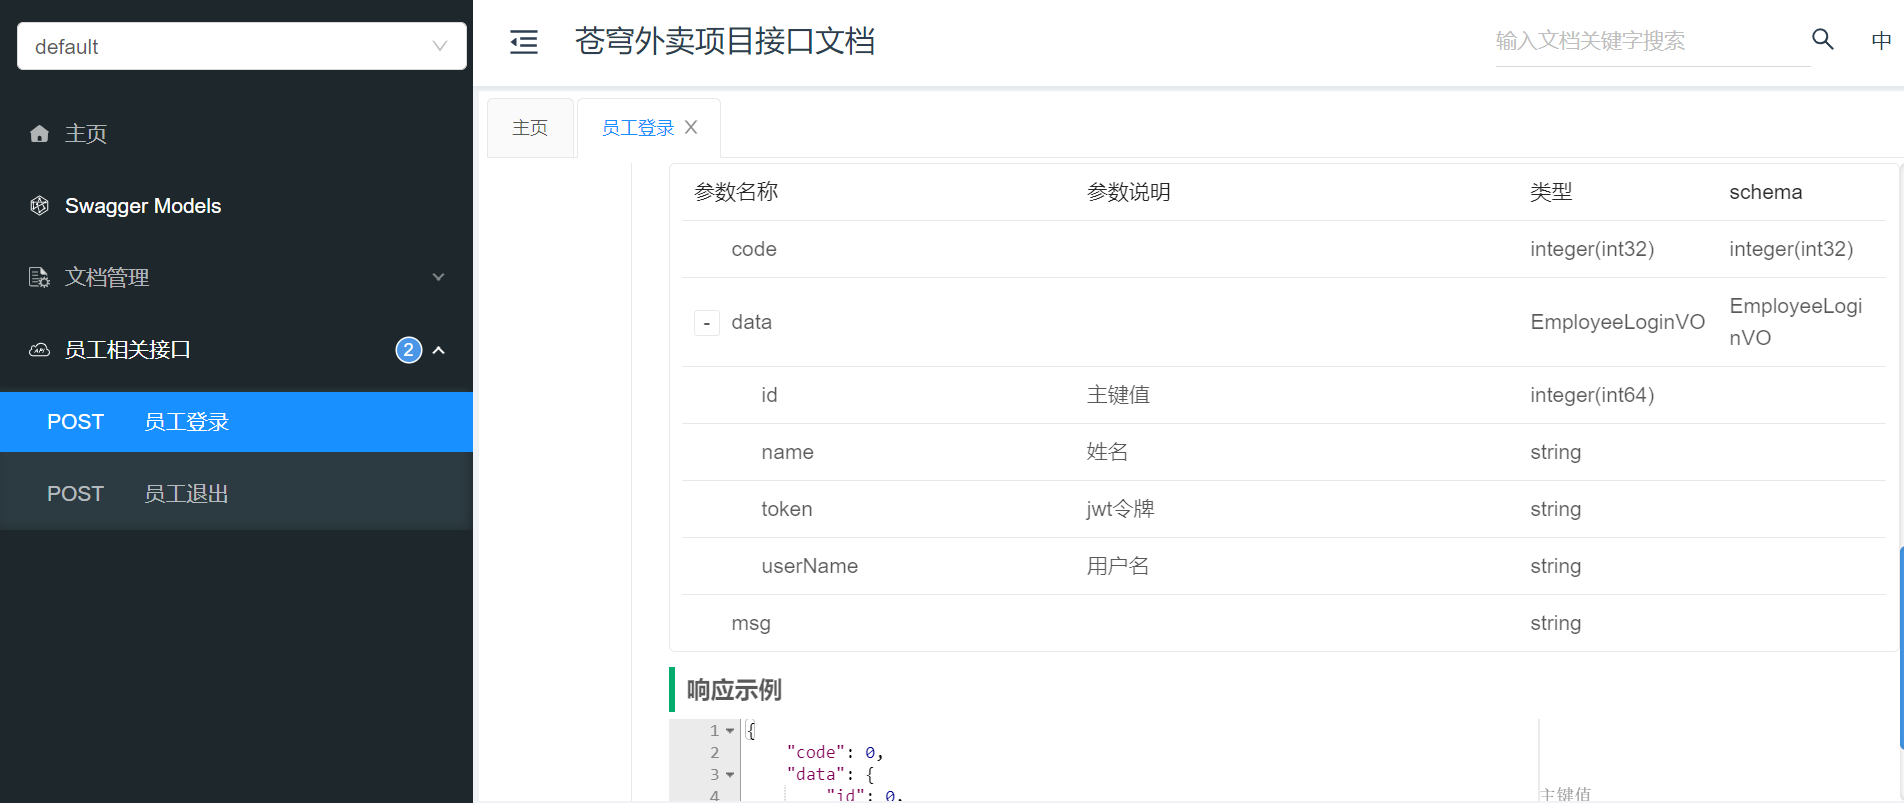


### 注解与返回对象（补充）

`@Api`与`@ApiOperation`描述接口，`@ApiModel`与`@ApiModelProperty`描述数据结构；它们本身不会自动验证输入，也不会实现鉴权。用户名、密码非空等校验需要相应的校验注解与方法配置。

讲义标注的 `EmployeeLoginVo.java` 与类名 `EmployeeLoginVO` 大小写不一致。Java public类的文件名应为 `EmployeeLoginVO.java`。最后的Controller代码把 `login` 方法体留空，是注解示例；保留初始工程已实现的登录方法体，否则缺少返回值不能编译。

登录DTO可包含密码，但VO应只包含前端需要的信息。文档示例不要填真实密钥或生产token。


## 复习速查、排错与验收（补充）

| 知识点 | 要记住什么 |
| --- | --- |
| 开发流程 | 需求有原型，设计有接口与表，编码后自测，测试后发布 |
| 项目两端 | 商家管理端维护经营，用户小程序完成消费流程 |
| Maven三模块 | common放公共类，pojo放数据对象，server放业务与启动类 |
| 登录分层 | Controller接收并响应，Service校验，Mapper查询 |
| 代理路径 | `/api/employee/login` 在Nginx中变成 `/admin/employee/login` |
| 密码 | 课程MD5只用于跟练；生产使用适合密码的哈希方案 |
| JWT | 登录签发token，后续请求由拦截器等组件校验 |
| 文档 | YApi维护约定，Swagger扫描代码，Knife4j提供调试页面 |

### 联调故障定位

| 问题 | 首先检查 | 下一步 |
| --- | --- | --- |
| 首页打不开 | Nginx进程与监听端口 | `nginx -t`、错误日志、静态资源路径 |
| 首页正常，登录502 | 8080后端是否启动 | 直连后端登录，检查Nginx代理目标 |
| 登录404 | `/api/`与`/admin/`的替换 | `proxy_pass`末尾斜杠与Controller映射 |
| 业务提示密码错误 | 数据库与代码使用明文还是MD5 | 检查测试数据、输入密码、是否二次哈希 |
| 数据库连接失败 | MySQL启动、端口、凭据、库名 | 当前profile与完整错误信息 |
| 文档404或没有接口 | 资源映射与Docket扫描 | 依赖版本、配置类生效、Controller注册 |

### 跟练验收清单

- [ ] 能解释开发、测试、生产环境的用途。
- [ ] 能列出管理端与用户端的核心业务。
- [ ] Maven模块可正常导入，明确实际JDK与Spring Boot版本。
- [ ] 初始化数据库后确认11张表与员工状态。
- [ ] Nginx首页可访问，后端直连登录可访问。
- [ ] 通过浏览器Network验证代理登录完整链路。
- [ ] 账号不存在、密码错误、账号禁用均能阻止登录。
- [ ] 正确登录返回VO与token，不返回密码，不记录明文密码日志。
- [ ] `doc.html`可打开并列出员工接口，登录调试成功。
- [ ] 有可追踪的初始代码版本，私密配置不提交到Git。

### 自测问题

1. 产品原型、UI效果图、接口文档分别解决什么问题？
2. 为什么将Employee实体直接返回前端可能泄露敏感字段？
3. `sky-common`、`sky-pojo`、`sky-server` 各放哪些代码？
4. `/api/employee/login` 怎样到达 `/admin/employee/login`？
5. `proxy_pass`的末尾斜杠在本章配置中有什么影响？
6. 为什么单独修改数据库密码或Service比对方式会让登录失败？
7. 为什么“成功签发JWT”还需要后续的令牌校验？
8. YApi与Swagger文档怎样相互核对？

> 下一章进入员工管理与分类管理，继续沿着“需求与接口、DTO/VO、Controller、Service、Mapper、联调验收”的顺序开发。
